# Time-Series Analysis: Exploratory Data Analysis (EDA)

This section explores the time-series dataset through statistical analysis, visualization, correlation analysis, trend and seasonality investigation, and stationarity testing.

In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose
from scipy.stats import zscore
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf

In [182]:
df = pd.read_csv("data/tesla_combined.csv")
df.head()

,Date,tsla_close,oil_close,lit_close,nasdag_close
0,2021-11-16,351.576660,80.760002,88.744553,15973.860352
1,2021-11-17,363.003326,78.360001,89.396736,15921.570312
2,2021-11-18,365.459991,79.010002,89.118584,15993.709961
3,2021-11-19,379.019989,76.099998,90.068108,16057.440430
4,2021-11-22,385.623322,76.750000,91.698555,15854.759766


## 1. Statistical Analysis

- Calculate descriptive statistics (mean, median, standard deviation, variance, minimum, maximum and quartiles).
- Generate statistical summaries.
- Perform daily, weekly and monthly aggregation.
- Examine distributions using histograms.

In [16]:
# Correct the NASDAQ column name
df.rename(columns={'nasdag_close': 'nasdaq_close'}, inplace=True)

# Convert Date into datetime format
df['Date'] = pd.to_datetime(df['Date'])

# Set Date as index
df.set_index('Date', inplace=True)

# Define numerical columns
columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

# Check dataset
print(df.head())
print(df.columns.tolist())
print(df.info())

            tsla_close  oil_close  lit_close  nasdaq_close
Date                                                      
2021-11-16  351.576660  80.760002  88.744553  15973.860352
2021-11-17  363.003326  78.360001  89.396736  15921.570312
2021-11-18  365.459991  79.010002  89.118584  15993.709961
2021-11-19  379.019989  76.099998  90.068108  16057.440430
2021-11-22  385.623322  76.750000  91.698555  15854.759766
DatetimeIndex(['2021-11-16', '2021-11-17', '2021-11-18', '2021-11-19',
               '2021-11-22', '2021-11-23', '2021-11-24', '2021-11-26',
               '2021-11-29', '2021-11-30',
               ...
               '2026-11-02', '2026-11-03', '2026-11-04', '2026-11-05',
               '2026-11-06', '2026-11-09', '2026-11-10', '2026-11-11',
               '2026-11-12', '2026-11-13'],
              dtype='datetime64[ns]', name='Date', length=1254, freq=None)
['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']


In [18]:
columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

descriptive_stats = pd.DataFrame({
    'Mean': df[columns].mean(),
    'Median': df[columns].median(),
    'Standard Deviation': df[columns].std(),
    'Variance': df[columns].var(),
    'Minimum': df[columns].min(),
    'Q1 (25%)': df[columns].quantile(0.25),
    'Q2 (50%)': df[columns].quantile(0.50),
    'Q3 (75%)': df[columns].quantile(0.75),
    'Maximum': df[columns].max()
})

print(descriptive_stats.round(2))

                  Mean    Median  Standard Deviation     Variance   Minimum  \
tsla_close      290.11    276.85               88.04      7751.78    108.10   
oil_close        79.24     77.53               13.49       182.04     55.27   
lit_close        58.02     60.44               14.56       211.91     31.49   
nasdaq_close  17350.55  16374.44             4873.92  23755135.34  10213.29   

              Q1 (25%)  Q2 (50%)  Q3 (75%)   Maximum  
tsla_close      219.23    276.85    361.78    489.88  
oil_close        69.66     77.53     86.91    123.70  
lit_close        43.64     60.44     69.64     91.70  
nasdaq_close  13280.01  16374.44  21367.79  27599.79  


In [19]:
# Statistical summaries: 

summary = df[columns].describe().T

summary['Variance'] = df[columns].var()
summary['Skewness'] = df[columns].skew()
summary['Kurtosis'] = df[columns].kurtosis()

print(summary.round(3))

               count       mean       std        min        25%        50%  \
tsla_close    1254.0    290.110    88.044    108.100    219.233    276.850   
oil_close     1254.0     79.239    13.492     55.270     69.660     77.530   
lit_close     1254.0     58.023    14.557     31.486     43.638     60.445   
nasdaq_close  1254.0  17350.548  4873.924  10213.290  13280.010  16374.435   

                    75%        max      Variance  Skewness  Kurtosis  
tsla_close      361.777    489.880  7.751778e+03     0.214    -1.010  
oil_close        86.908    123.700  1.820440e+02     0.711     0.184  
lit_close        69.637     91.699  2.119080e+02     0.077    -1.115  
nasdaq_close  21367.788  27599.789  2.375514e+07     0.443    -0.988  


## 2. Time-Series Visualization

- Plot all time series individually.
- Create comparative line plots.
- Visualize seasonal patterns.
- Generate correlation heatmaps.
- Generate autocorrelation (ACF) plots.

In [152]:
# Daily aggregation:

daily_data = df[columns].resample('D').mean()

print(daily_data.head())

            tsla_close  oil_close  lit_close  nasdaq_close
Date                                                      
2021-11-16  351.576660  80.760002  88.744553  15973.860352
2021-11-17  363.003326  78.360001  89.396736  15921.570312
2021-11-18  365.459991  79.010002  89.118584  15993.709961
2021-11-19  379.019989  76.099998  90.068108  16057.440430
2021-11-20         NaN        NaN        NaN           NaN


In [22]:
# Weekly aggregation: 

weekly_data = df[columns].resample('W').mean()

print(weekly_data.head())

            tsla_close  oil_close  lit_close  nasdaq_close
Date                                                      
2021-11-21  364.764992  78.557501  89.331995  15986.645264
2021-11-28  371.985001  75.447500  90.120848  15741.697510
2021-12-05  365.088000  66.892000  88.086618  15408.272070
2021-12-12  343.370007  71.302000  86.212558  15569.406055
2021-12-19  317.359991  71.226001  83.264313  15313.321875


In [24]:
# Monthly aggregation: 

monthly_data = df[columns].resample('ME').mean()

print(monthly_data.head())

            tsla_close   oil_close  lit_close  nasdaq_close
Date                                                       
2021-11-30  370.758331   75.215000  89.726662  15823.389160
2021-12-31  339.629999   71.690001  83.230977  15474.431729
2022-01-31  336.722830   82.979000  77.426783  14531.377490
2022-02-28  292.961577   91.628947  73.589149  13898.728413
2022-03-31  304.793186  108.262174  70.074195  13623.262950


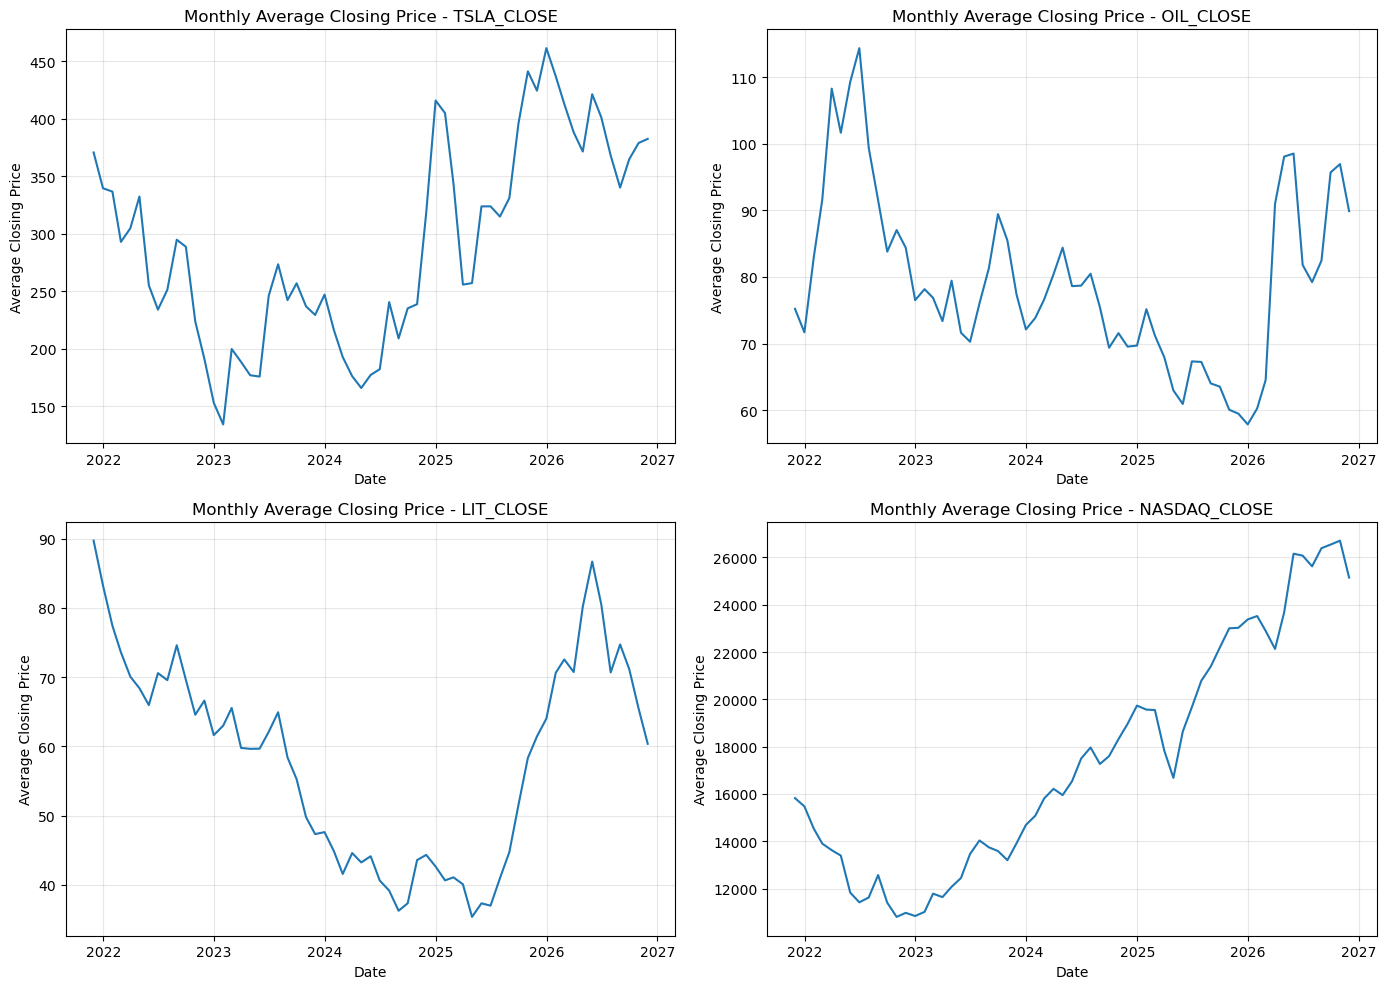

In [29]:
# Visualizing Monthly average: 

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(columns, axes.flatten()):
    ax.plot(monthly_data.index, monthly_data[column])

    ax.set_title(f'Monthly Average Closing Price - {column.upper()}')
    ax.set_xlabel('Date')
    ax.set_ylabel('Average Closing Price')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

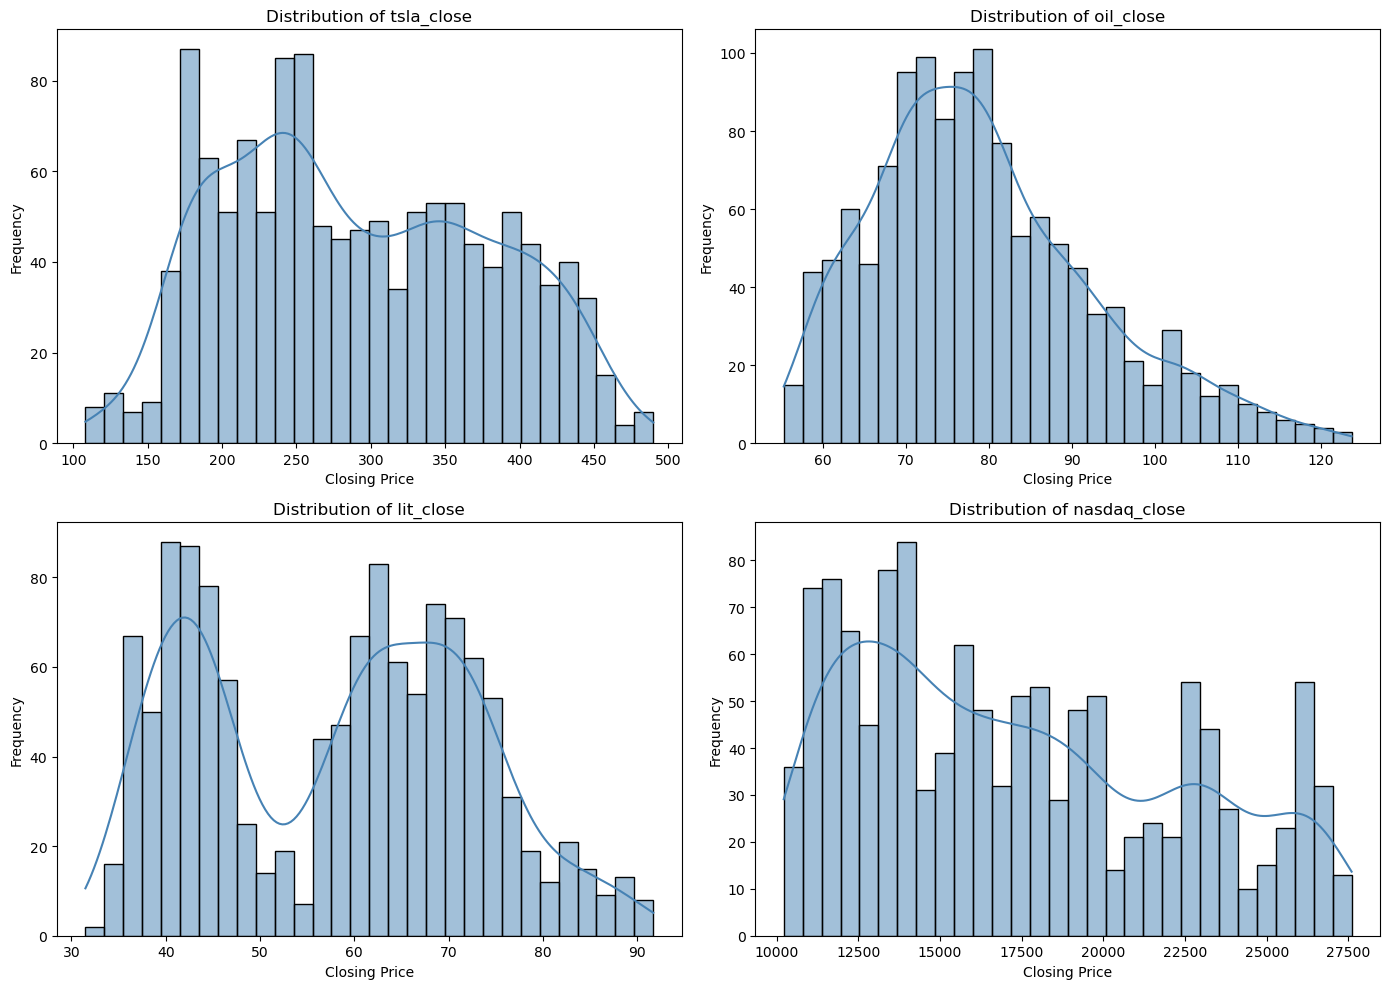

In [30]:
# Examining distributions with histograms: 

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

for column, ax in zip(columns, axes.flatten()):
    sns.histplot(
        df[column].dropna(),
        bins=30,
        kde=True,
        ax=ax,
        color='steelblue'
    )

    ax.set_title(f'Distribution of {column}')
    ax.set_xlabel('Closing Price')
    ax.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

## 3. Correlation Analysis

- Calculate Pearson correlation coefficients.
- Generate a correlation matrix.
- Visualize relationships using a heatmap.
- Interpret important correlations between variables.

In [37]:
# Pearson correlations: 

columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

correlation_matrix = df[columns].corr(method='pearson')

# Focus on correlations with Tesla
tsla_correlations = correlation_matrix['tsla_close'].sort_values(
    ascending=False
)

print("Correlations with Tesla:")
print(tsla_correlations.round(3))

Correlations with Tesla:
tsla_close      1.000
nasdaq_close    0.750
lit_close       0.347
oil_close      -0.145
Name: tsla_close, dtype: float64


In [38]:
# Correlation matrix: 

correlation_matrix = df[columns].corr(method='pearson')

print("Pearson Correlation Matrix:")
print(correlation_matrix.round(3))

Pearson Correlation Matrix:
              tsla_close  oil_close  lit_close  nasdaq_close
tsla_close         1.000     -0.145      0.347         0.750
oil_close         -0.145      1.000      0.451        -0.222
lit_close          0.347      0.451      1.000         0.076
nasdaq_close       0.750     -0.222      0.076         1.000


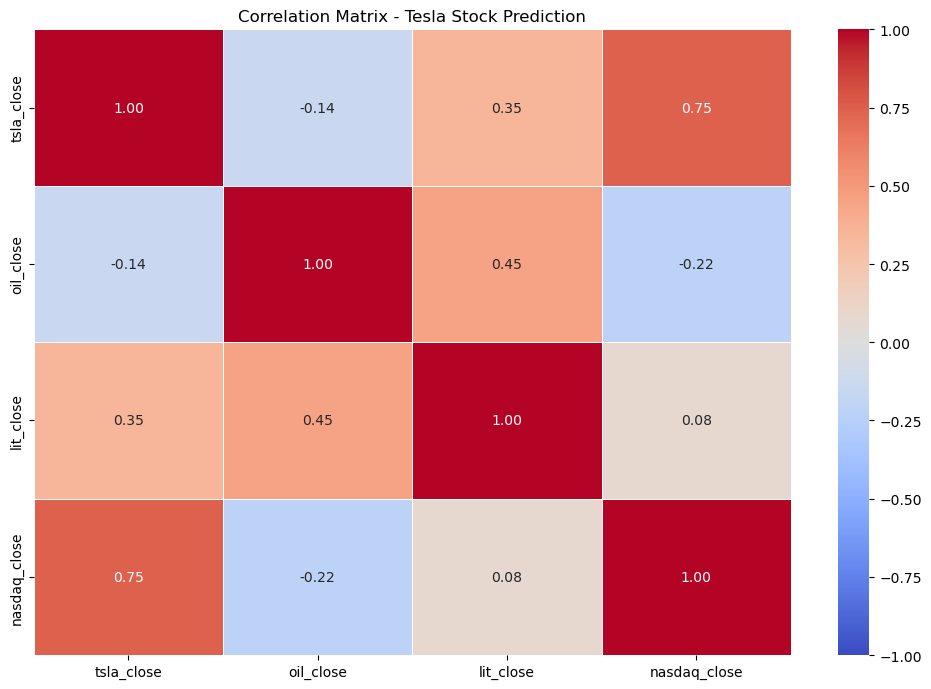

In [39]:
# Visualizing relationships with a heatmap: 

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Matrix - Tesla Stock Prediction')
plt.tight_layout()
plt.show()

Daily Return Correlations with Tesla:
tsla_close      1.000
nasdaq_close    0.656
lit_close       0.483
oil_close      -0.013
Name: tsla_close, dtype: float64


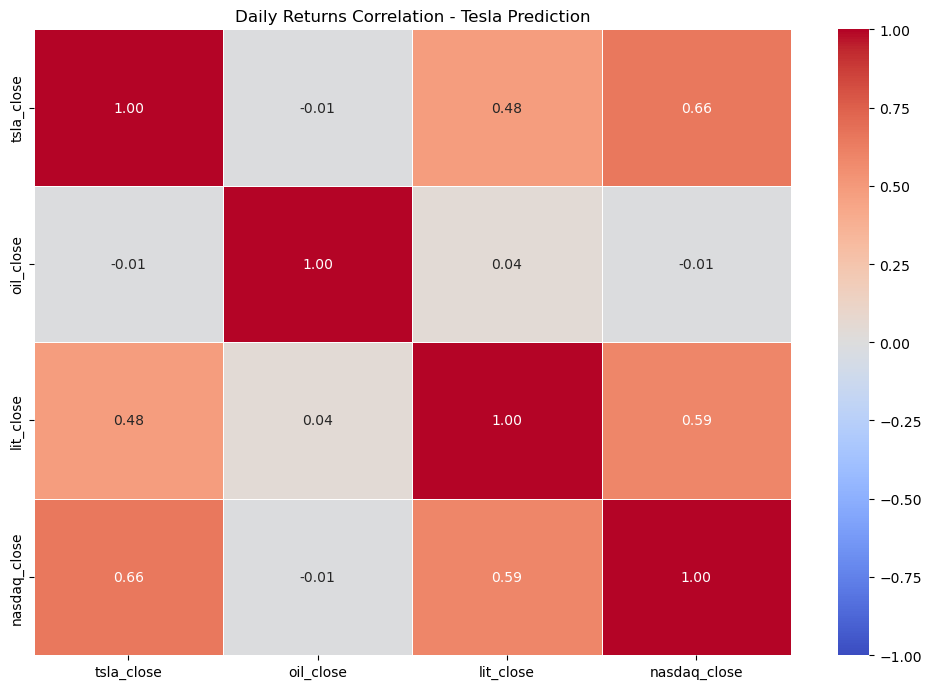

In [42]:
# Identifying strongest correlations: 

daily_returns = df[columns].pct_change().dropna()

return_correlation = daily_returns.corr(method='pearson')

print("Daily Return Correlations with Tesla:")
print(return_correlation['tsla_close'].sort_values(ascending=False).round(3))

plt.figure(figsize=(10, 7))

sns.heatmap(
    return_correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Daily Returns Correlation - Tesla Prediction')
plt.tight_layout()
plt.show()

## 4. Trend and Seasonality Analysis

- Investigate long-term trends.
- Identify recurring seasonal patterns.
- Analyze daily, weekly and monthly patterns where relevant.
- Perform additive and multiplicative decomposition.
- Analyze trend, seasonal and residual components.

In [43]:
# Let's prepare the dataseries: 

# Select Tesla closing prices
tsla = df['tsla_close'].dropna()

# Check the data
print(tsla.head())
print(tsla.tail())

# Check frequency and date range
print("Number of observations:", len(tsla))
print("Start date:", tsla.index.min())
print("End date:", tsla.index.max())

Date
2021-11-16    351.576660
2021-11-17    363.003326
2021-11-18    365.459991
2021-11-19    379.019989
2021-11-22    385.623322
Name: tsla_close, dtype: float64
Date
2026-11-09    378.049988
2026-11-10    379.779999
2026-11-11    390.839996
2026-11-12    397.450012
2026-11-13    390.220001
Name: tsla_close, dtype: float64
Number of observations: 1254
Start date: 2021-11-16 00:00:00
End date: 2026-11-13 00:00:00


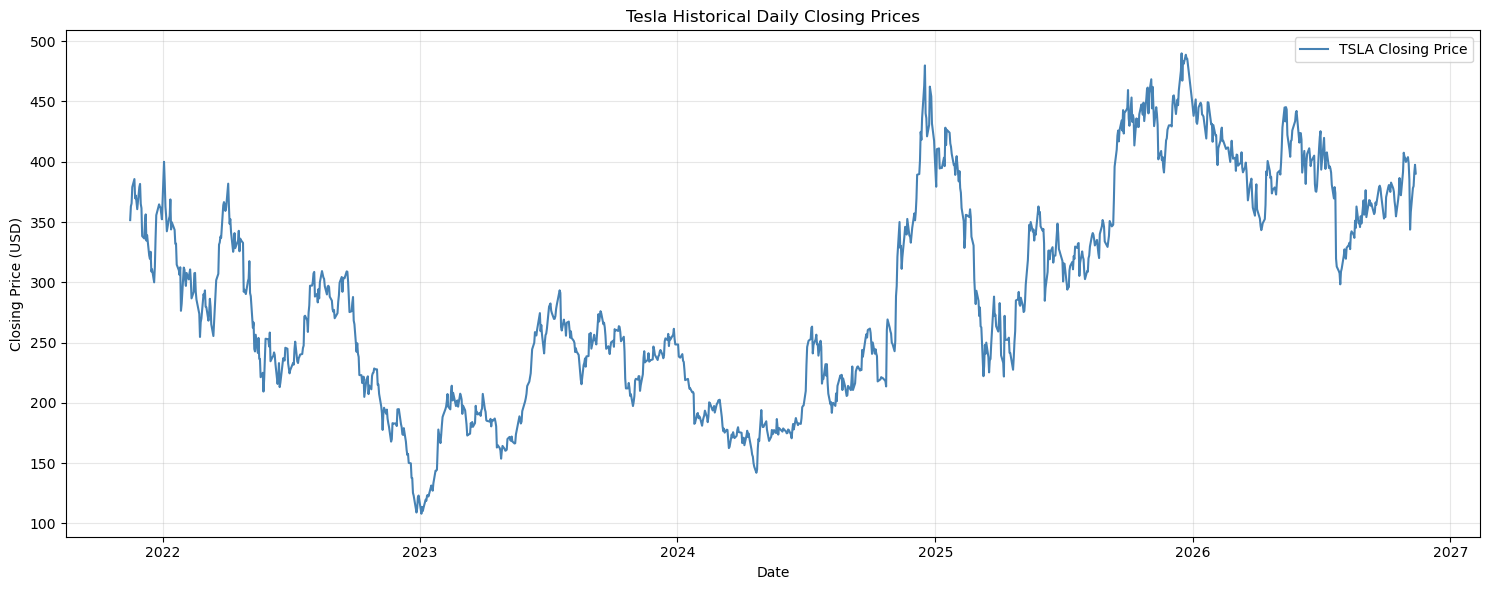

In [45]:
# Long term trends: 

plt.figure(figsize=(15, 6))

plt.plot(tsla, color='steelblue', label='TSLA Closing Price')

plt.title('Tesla Historical Daily Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

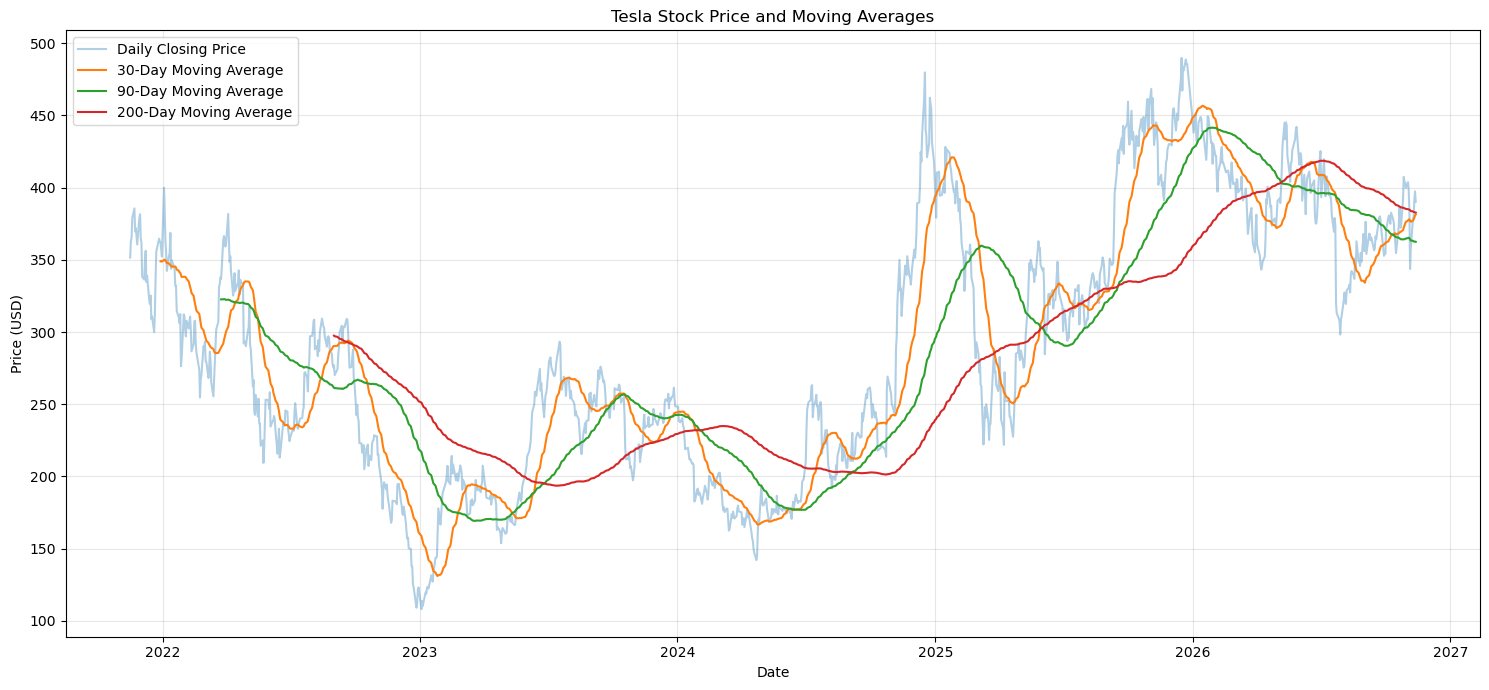

In [50]:
# Calculating the MA: 

tsla_ma = pd.DataFrame(index=tsla.index)

tsla_ma['Closing Price'] = tsla
tsla_ma['30-Day MA'] = tsla.rolling(window=30).mean()
tsla_ma['90-Day MA'] = tsla.rolling(window=90).mean()
tsla_ma['200-Day MA'] = tsla.rolling(window=200).mean()

plt.figure(figsize=(15, 7))

plt.plot(tsla_ma['Closing Price'], alpha=0.35, label='Daily Closing Price')
plt.plot(tsla_ma['30-Day MA'], label='30-Day Moving Average')
plt.plot(tsla_ma['90-Day MA'], label='90-Day Moving Average')
plt.plot(tsla_ma['200-Day MA'], label='200-Day Moving Average')

plt.title('Tesla Stock Price and Moving Averages')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Investigating recurring seasonal patterns: 

_By week day_

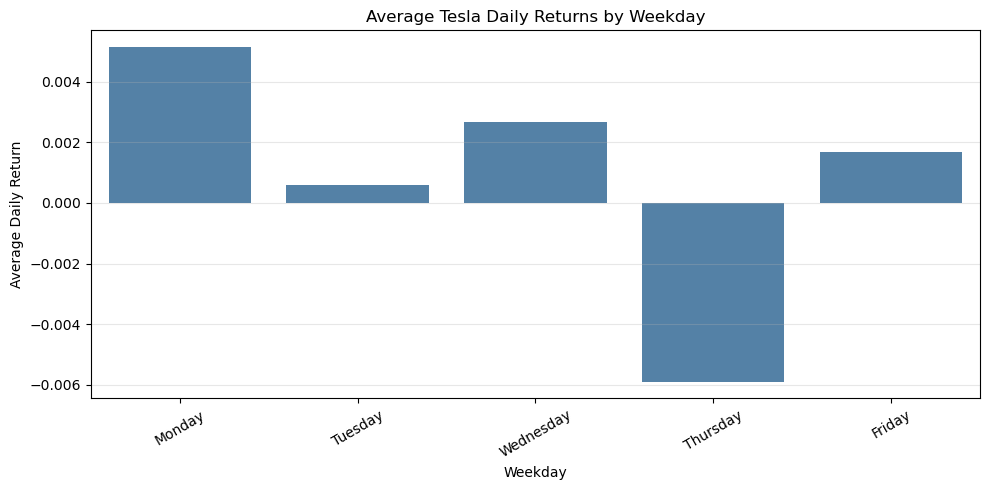

In [51]:
# Calculate daily percentage returns
tsla_returns = tsla.pct_change().dropna()

# Group returns by weekday
weekday_returns = tsla_returns.groupby(
    tsla_returns.index.day_name()
).mean()

# Arrange weekdays in calendar order
weekday_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday'
]

weekday_returns = weekday_returns.reindex(weekday_order)

# Plot weekday performance
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_returns.index,
    y=weekday_returns.values,
    color='steelblue'
)

plt.title('Average Tesla Daily Returns by Weekday')
plt.xlabel('Weekday')
plt.ylabel('Average Daily Return')
plt.xticks(rotation=30)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

_By week_

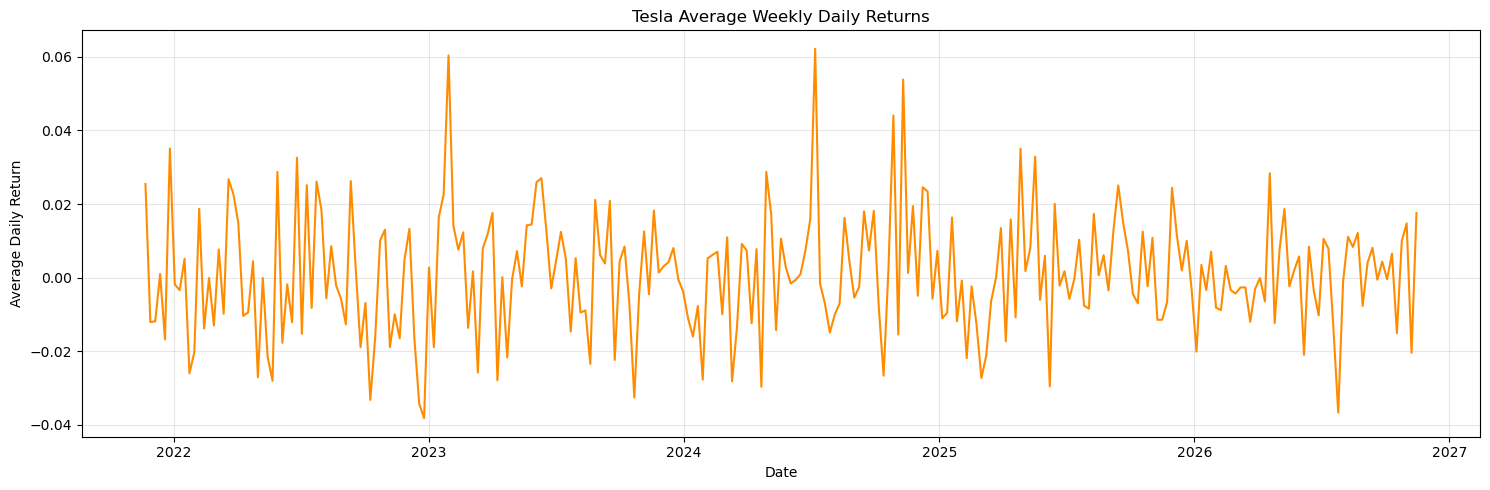

In [54]:
# Weekly returns: 

weekly_returns = tsla_returns.resample('W').mean()

plt.figure(figsize=(15, 5))

plt.plot(weekly_returns, color='darkorange')

plt.title('Tesla Average Weekly Daily Returns')
plt.xlabel('Date')
plt.ylabel('Average Daily Return')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

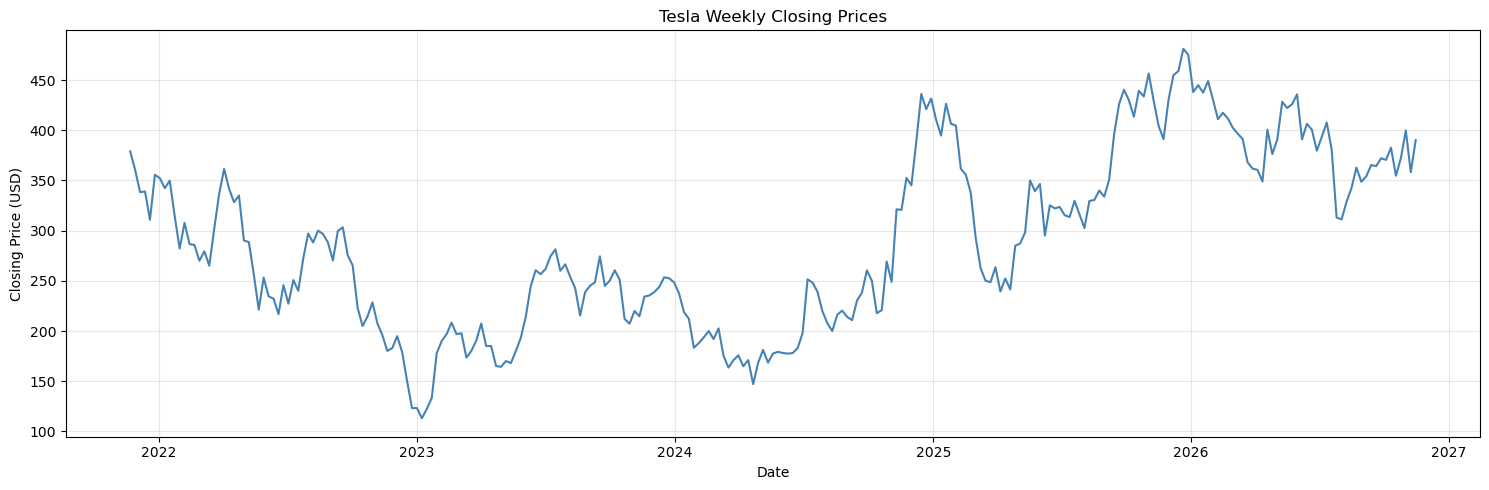

In [55]:
# Weekly closing prices: 

weekly_closing = tsla.resample('W').last()

plt.figure(figsize=(15, 5))

plt.plot(weekly_closing, color='steelblue')

plt.title('Tesla Weekly Closing Prices')
plt.xlabel('Date')
plt.ylabel('Closing Price (USD)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

_By month:_ 

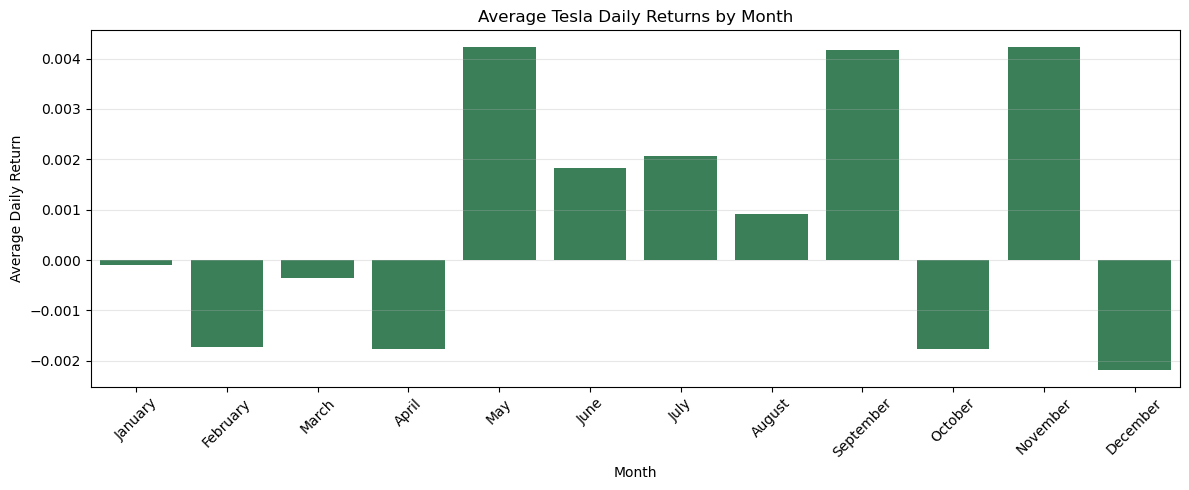

In [58]:
# Calculate average returns for each calendar month
monthly_returns = tsla_returns.groupby(
    tsla_returns.index.month
).mean()

month_names = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_returns.index = month_names

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_returns.index,
    y=monthly_returns.values,
    color='seagreen'
)

plt.title('Average Tesla Daily Returns by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Return')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# Compositions:

_Additive:_

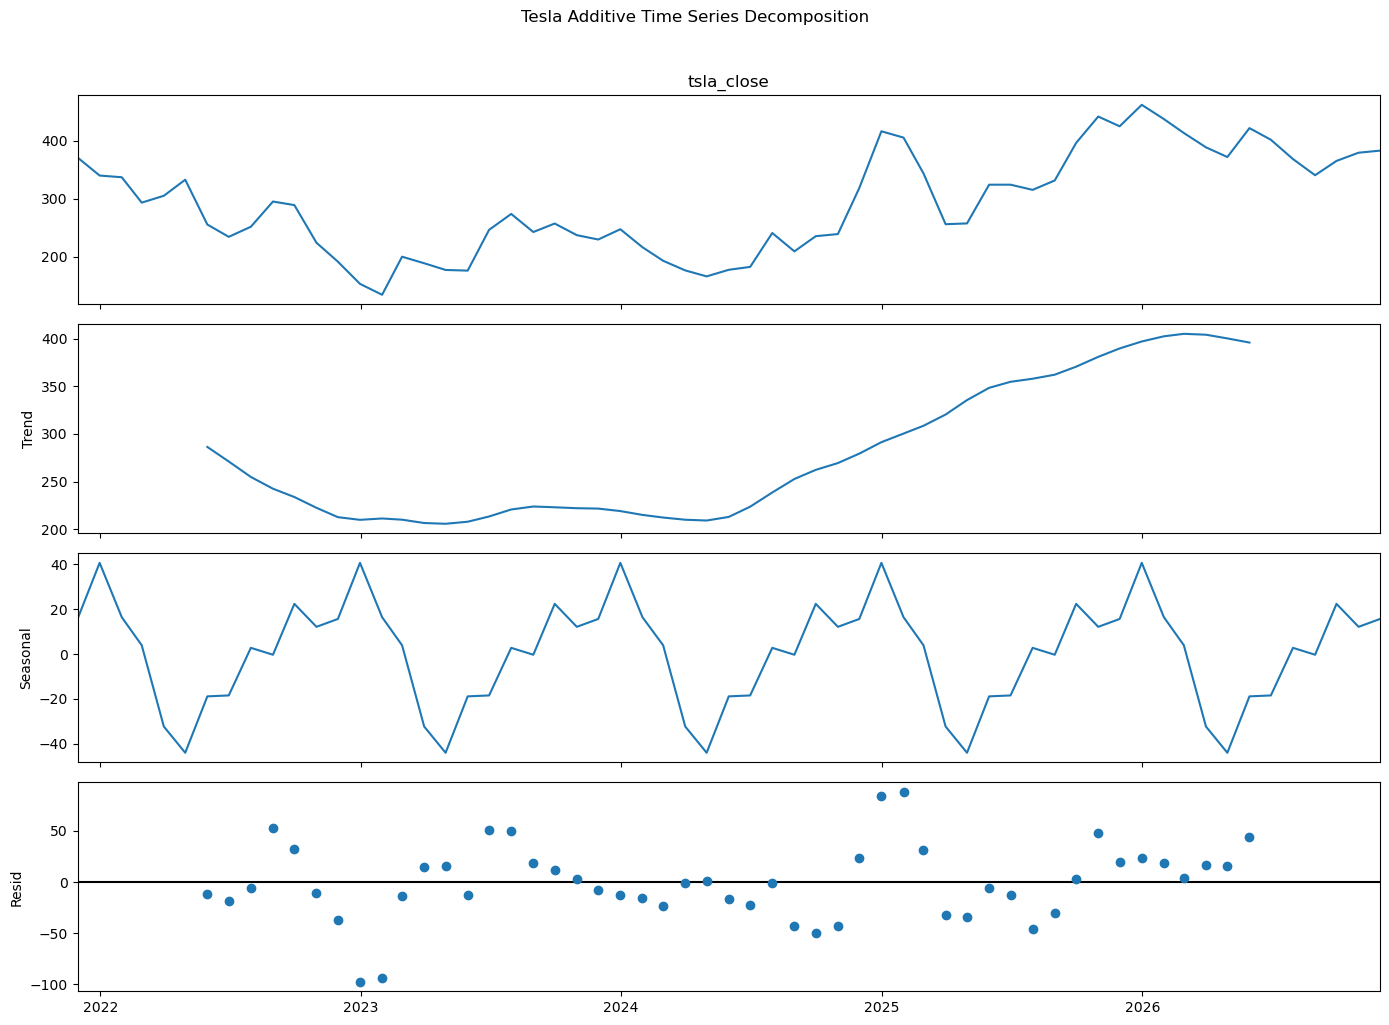

In [60]:
# Convert Tesla prices into monthly averages
tsla_monthly = tsla.resample('ME').mean()

# Additive decomposition
additive_decomposition = seasonal_decompose(
    tsla_monthly,
    model='additive',
    period=12
)

# Plot decomposition
fig = additive_decomposition.plot()

fig.set_size_inches(14, 10)
fig.suptitle('Tesla Additive Time Series Decomposition', y=1.02)

plt.tight_layout()
plt.show()

_Multiplicative:_

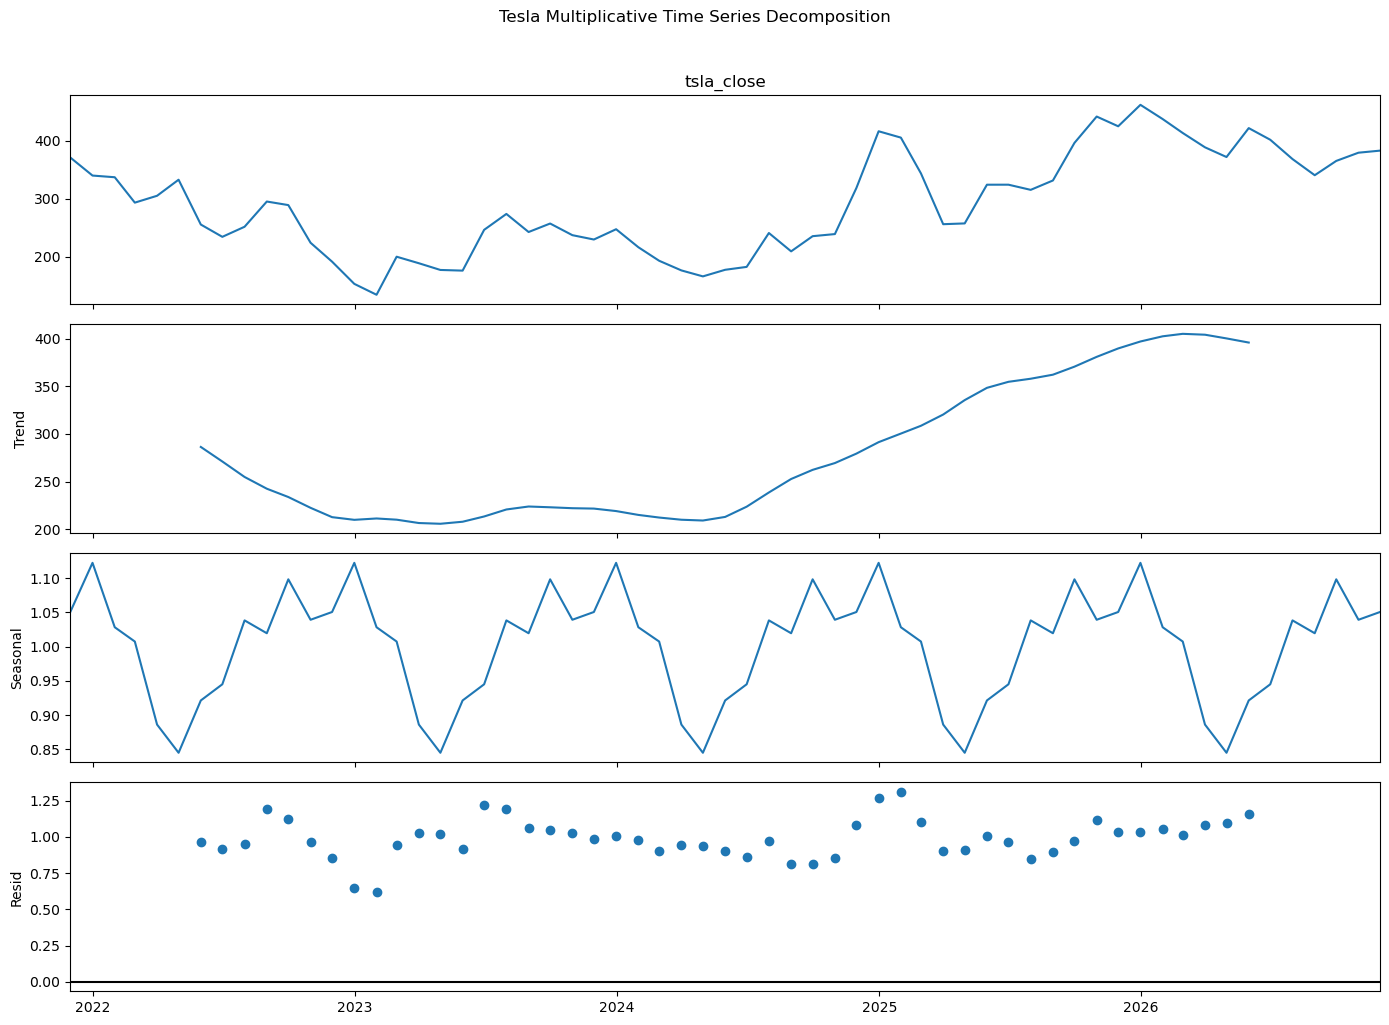

In [63]:
# Multiplicative decomposition
multiplicative_decomposition = seasonal_decompose(
    tsla_monthly,
    model='multiplicative',
    period=12
)

# Plot decomposition
fig = multiplicative_decomposition.plot()

fig.set_size_inches(14, 10)
fig.suptitle('Tesla Multiplicative Time Series Decomposition', y=1.02)

plt.tight_layout()
plt.show()

# Analyzing trend, seasonal, and residual components: 

*Trend component*

trend = additive_decomposition.trend

plt.figure(figsize=(14, 5))

plt.plot(trend, color='blue')

plt.title('Tesla Long-Term Trend Component')
plt.xlabel('Date')
plt.ylabel('Trend Price (USD)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

*Seasonal component*

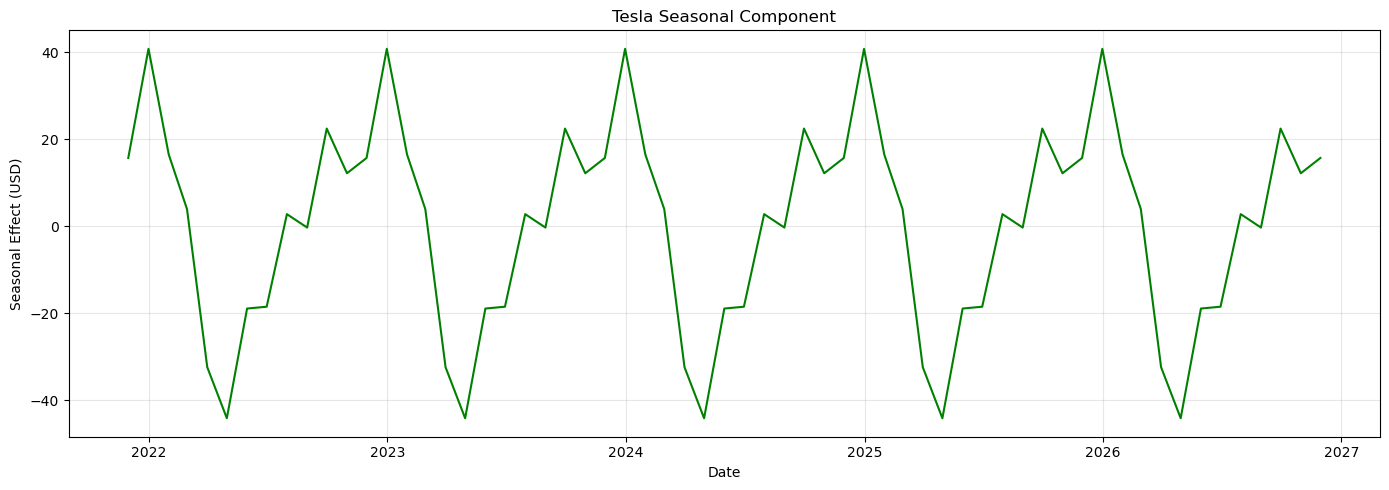

In [70]:
seasonal = additive_decomposition.seasonal

plt.figure(figsize=(14, 5))

plt.plot(seasonal, color='green')

plt.title('Tesla Seasonal Component')
plt.xlabel('Date')
plt.ylabel('Seasonal Effect (USD)')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

*Residual component*

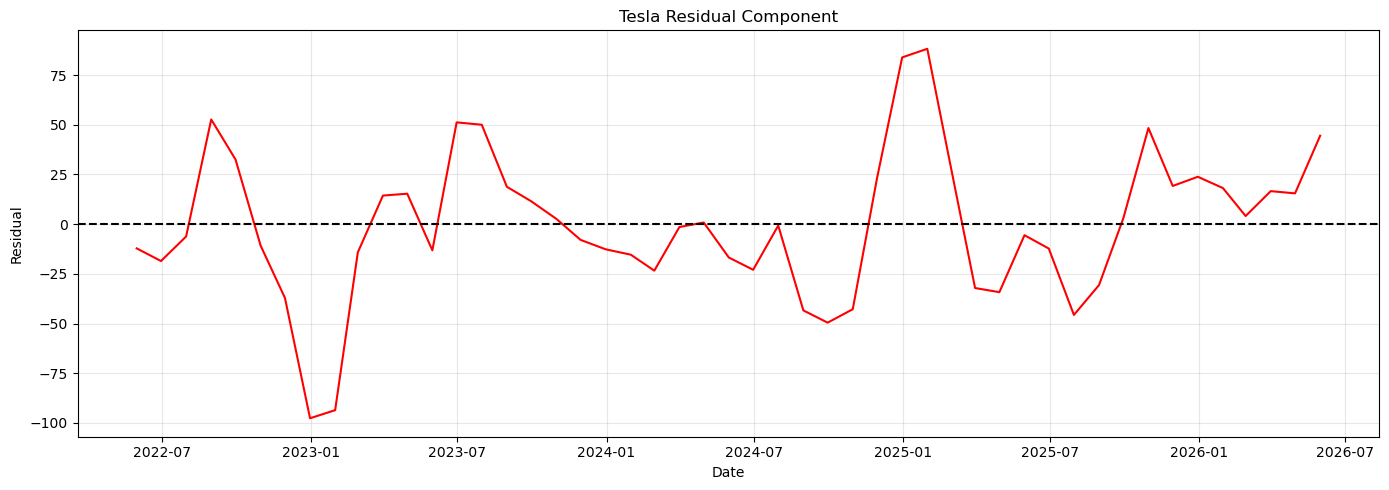

In [72]:
residual = additive_decomposition.resid

plt.figure(figsize=(14, 5))

plt.plot(residual, color='red')

plt.axhline(y=0, color='black', linestyle='--')

plt.title('Tesla Residual Component')
plt.xlabel('Date')
plt.ylabel('Residual')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [74]:
# Residual statistics: 

residual_stats = pd.Series({
    'Mean': residual.mean(),
    'Standard Deviation': residual.std(),
    'Minimum': residual.min(),
    'Maximum': residual.max(),
    'Variance': residual.var()
})

print(residual_stats.round(3))

Mean                    -0.638
Standard Deviation      37.188
Minimum                -97.630
Maximum                 88.214
Variance              1382.979
dtype: float64


## 5. Stationarity Analysis

- Perform the Augmented Dickey-Fuller (ADF) test.
- Interpret ADF statistics and p-values.
- Apply log transformations where appropriate.
- Apply first-order differencing.
- Compare stationarity before and after transformations.

_ADF test_

In [82]:
# Variables to test
columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

# Perform ADF test
for col in columns:
    result = adfuller(df[col].dropna())

    print(f'\nADF Test: {col}')
    print(f'ADF Statistic: {result[0]:.6f}')
    print(f'p-value: {result[1]:.6f}')
    print(f'Critical Values: {result[4]}')

    if result[1] <= 0.05:
        print('Result: Stationary')
    else:
        print('Result: Non-stationary')



ADF Test: tsla_close
ADF Statistic: -2.058329
p-value: 0.261597
Critical Values: {'1%': np.float64(-3.4355796466416777), '5%': np.float64(-2.863849421064024), '10%': np.float64(-2.5679995625056926)}
Result: Non-stationary

ADF Test: oil_close
ADF Statistic: -2.519608
p-value: 0.110776
Critical Values: {'1%': np.float64(-3.435673305025808), '5%': np.float64(-2.863890744031555), '10%': np.float64(-2.56802156936202)}
Result: Non-stationary

ADF Test: lit_close
ADF Statistic: -2.217378
p-value: 0.199999
Critical Values: {'1%': np.float64(-3.4355796466416777), '5%': np.float64(-2.863849421064024), '10%': np.float64(-2.5679995625056926)}
Result: Non-stationary

ADF Test: nasdaq_close
ADF Statistic: -0.167332
p-value: 0.942305
Critical Values: {'1%': np.float64(-3.4355796466416777), '5%': np.float64(-2.863849421064024), '10%': np.float64(-2.5679995625056926)}
Result: Non-stationary


_interpreting results and p-values:_

In [84]:
adf_results = []

for col in columns:
    result = adfuller(df[col].dropna())

    adf_results.append({
        'Variable': col,
        'ADF Statistic': result[0],
        'p-value': result[1],
        '1% Critical Value': result[4]['1%'],
        '5% Critical Value': result[4]['5%'],
        '10% Critical Value': result[4]['10%'],
        'Stationarity': 'Stationary' if result[1] <= 0.05 else 'Non-stationary'
    })

adf_results_df = pd.DataFrame(adf_results)

print(adf_results_df)

       Variable  ADF Statistic   p-value  1% Critical Value  \
0    tsla_close      -2.058329  0.261597          -3.435580   
1     oil_close      -2.519608  0.110776          -3.435673   
2     lit_close      -2.217378  0.199999          -3.435580   
3  nasdaq_close      -0.167332  0.942305          -3.435580   

   5% Critical Value  10% Critical Value    Stationarity  
0          -2.863849           -2.568000  Non-stationary  
1          -2.863891           -2.568022  Non-stationary  
2          -2.863849           -2.568000  Non-stationary  
3          -2.863849           -2.568000  Non-stationary  


_Applying Log transformation:_

In [89]:
columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

df_log = df.copy()

for col in columns:
    df_log[f'{col}_log'] = np.log(df_log[col])

df_log[[f'{col}_log' for col in columns]].head()

,tsla_close_log,oil_close_log,lit_close_log,nasdaq_close_log
Date,,,,
2021-11-16,5.862428,4.391482,4.485762,9.678709
2021-11-17,5.894412,4.361314,4.493084,9.675430
2021-11-18,5.901157,4.369574,4.489968,9.679951
2021-11-19,5.937589,4.332048,4.500566,9.683928
2021-11-22,5.954861,4.340553,4.518507,9.671225


_First order differencing:_

In [91]:
df_diff = df_log.copy()

for col in columns:
    df_diff[f'{col}_diff'] = df_log[f'{col}_log'].diff()

df_diff = df_diff.dropna(
    subset=[f'{col}_diff' for col in columns]
)

df_diff[[f'{col}_diff' for col in columns]].head()

,tsla_close_diff,oil_close_diff,lit_close_diff,nasdaq_close_diff
Date,,,,
2021-11-17,0.031984,-0.030168,0.007322,-0.003279
2021-11-18,0.006745,0.008261,-0.003116,0.004521
2021-11-19,0.036432,-0.037526,0.010598,0.003977
2021-11-22,0.017272,0.008505,0.017940,-0.012703
2021-11-23,-0.042232,0.022545,-0.017302,-0.005034


_ADF test after log transform:_

In [93]:
for col in columns:
    result = adfuller(df_log[f'{col}_log'].dropna())

    print(f'\n{col} - Log Transformation')
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Stationary:', result[1] <= 0.05)


tsla_close - Log Transformation
ADF Statistic: -2.017966533248382
p-value: 0.2787513837334615
Stationary: False

oil_close - Log Transformation
ADF Statistic: -2.414841798611125
p-value: 0.13759116322298975
Stationary: False

lit_close - Log Transformation
ADF Statistic: -1.9203864562405157
p-value: 0.322532285207761
Stationary: False

nasdaq_close - Log Transformation
ADF Statistic: -0.341730225532586
p-value: 0.9193826161183069
Stationary: False


_ADF test after differencing:_

In [95]:
for col in columns:
    result = adfuller(df_diff[f'{col}_diff'].dropna())

    print(f'\n{col} - First Differencing')
    print('ADF Statistic:', result[0])
    print('p-value:', result[1])
    print('Stationary:', result[1] <= 0.05)


tsla_close - First Differencing
ADF Statistic: -36.21855674269165
p-value: 0.0
Stationary: True

oil_close - First Differencing
ADF Statistic: -7.6692770330502995
p-value: 1.609765973189764e-11
Stationary: True

lit_close - First Differencing
ADF Statistic: -36.30105571683354
p-value: 0.0
Stationary: True

nasdaq_close - First Differencing
ADF Statistic: -36.647375296462364
p-value: 0.0
Stationary: True


# Part 2 — Data Quality and Preprocessing

This section investigates data quality issues, identifies unusual observations, examines missing-data patterns and evaluates different missing-value imputation techniques.

## 6. Outlier and Missing Data Analysis

### 6.1 Outlier Detection

- Z-Score Detection.
- Rolling IQR Method.
- Visualize and investigate detected outliers.

### 6.2 Missing Data Analysis

- Identify missing values.
- Visualize missing-data patterns.
- Perform gap analysis.
- Simulate missing values where appropriate.

### Outlier Detection: 

In [96]:
# Z-score detection

In [98]:
columns = ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']

# Calculate Z-scores
z_scores = df[columns].apply(
    lambda x: zscore(x, nan_policy='omit')
)

# Identify outliers (Z-score > 3 or < -3)
outliers_z = z_scores.abs() > 3

# Count outliers per variable
print("Outliers detected using Z-Score:")
print(outliers_z.sum())

# Display detected outliers
for col in columns:
    print(f'\n{col}:')
    print(df.loc[outliers_z[col], col])

Outliers detected using Z-Score:
tsla_close      0
oil_close       5
lit_close       0
nasdaq_close    0
dtype: int64

tsla_close:
Series([], Name: tsla_close, dtype: float64)

oil_close:
Date
2022-03-08    123.699997
2022-06-08    122.110001
2022-06-09    121.510002
2022-06-10    120.669998
2022-06-13    120.930000
Name: oil_close, dtype: float64

lit_close:
Series([], Name: lit_close, dtype: float64)

nasdaq_close:
Series([], Name: nasdaq_close, dtype: float64)


In [ ]:
# Rolling IQR

In [100]:
window = 30

outliers_iqr = pd.DataFrame(
    False,
    index=df.index,
    columns=columns
)

for col in columns:

    rolling_q1 = df[col].rolling(
        window=window,
        min_periods=15
    ).quantile(0.25)

    rolling_q3 = df[col].rolling(
        window=window,
        min_periods=15
    ).quantile(0.75)

    rolling_iqr = rolling_q3 - rolling_q1

    lower_bound = rolling_q1 - 1.5 * rolling_iqr
    upper_bound = rolling_q3 + 1.5 * rolling_iqr

    outliers_iqr[col] = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    )

print("Rolling IQR Outlier Counts:")
print(outliers_iqr.sum())

Rolling IQR Outlier Counts:
tsla_close      114
oil_close        85
lit_close        72
nasdaq_close     69
dtype: int64


In [101]:
# Visualizing detected outliers: 

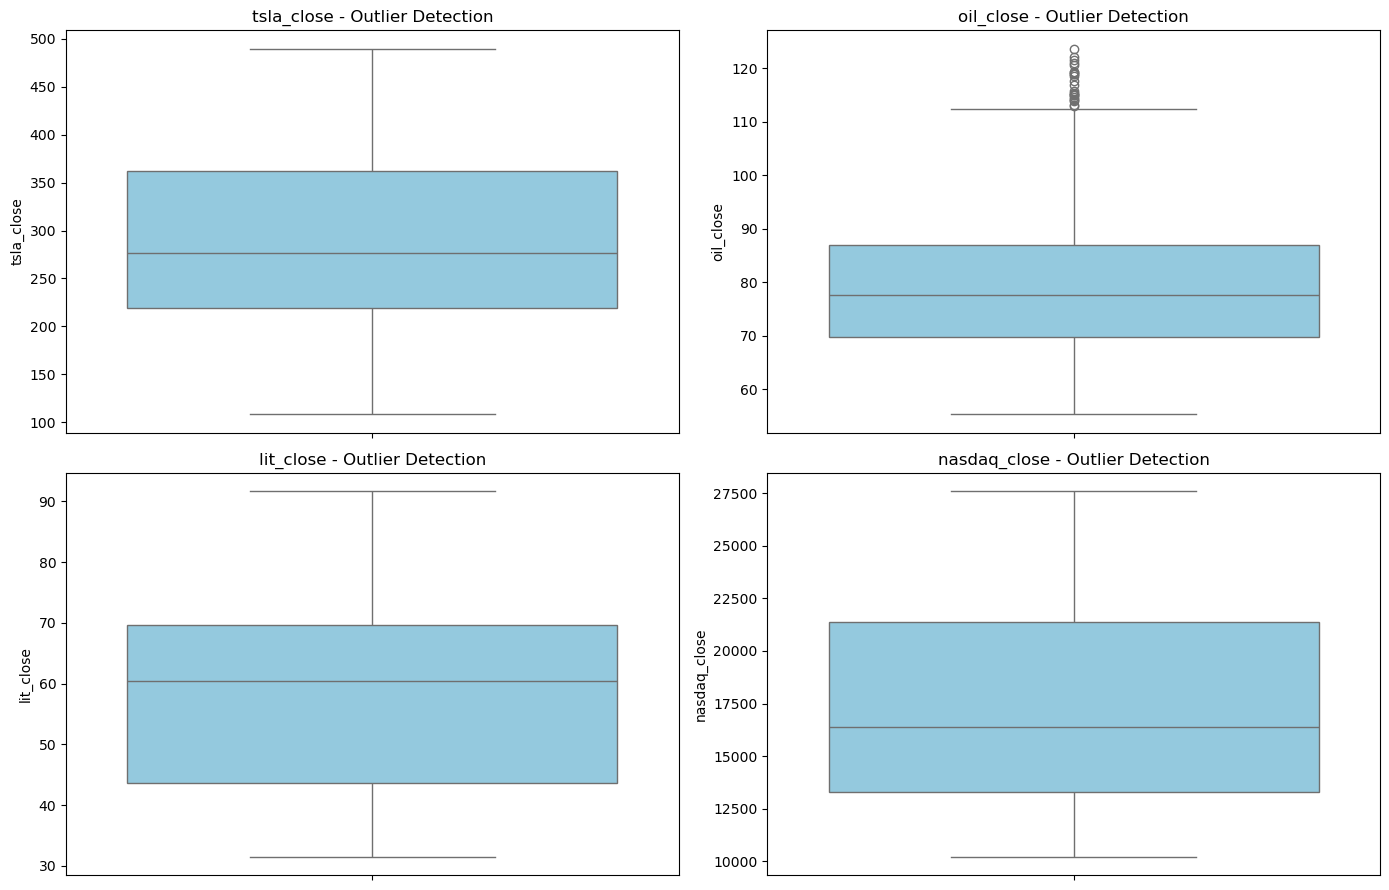

In [102]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, col in zip(axes.flatten(), columns):
    sns.boxplot(y=df[col], ax=ax, color='skyblue')
    ax.set_title(f'{col} - Outlier Detection')

plt.tight_layout()
plt.show()

In [103]:
# Closing price with detected outliers: 

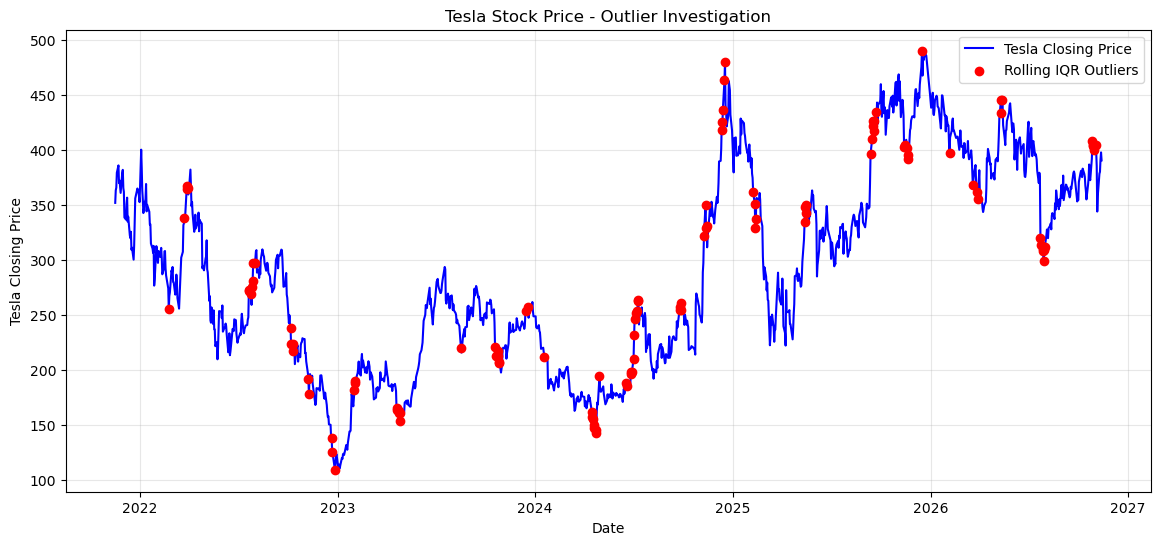

In [105]:
plt.figure(figsize=(14, 6))

plt.plot(
    df.index,
    df['tsla_close'],
    label='Tesla Closing Price',
    color='blue'
)

plt.scatter(
    df.index[outliers_iqr['tsla_close']],
    df.loc[outliers_iqr['tsla_close'], 'tsla_close'],
    color='red',
    label='Rolling IQR Outliers',
    zorder=5
)

plt.title('Tesla Stock Price - Outlier Investigation')
plt.xlabel('Date')
plt.ylabel('Tesla Closing Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [106]:
# Displaying such outliers: 

In [107]:
tesla_outliers = df.loc[
    outliers_iqr['tsla_close'],
    ['tsla_close', 'oil_close', 'lit_close', 'nasdaq_close']
]

print("Tesla Outlier Observations:")
display(tesla_outliers)

Tesla Outlier Observations:


,tsla_close,oil_close,lit_close,nasdaq_close
Date,,,,
2022-02-23,254.679993,92.099998,70.780151,13037.490234
2022-03-24,337.973328,112.339996,73.499153,14191.839844
2022-03-28,363.946655,105.959999,71.750534,14354.900391
2022-03-29,366.523346,104.239998,73.470322,14619.639648
2022-03-30,364.663330,107.820000,74.507957,14442.269531
...,...,...,...,...
2026-10-27,407.459991,99.900002,62.630001,26477.810547
2026-10-28,404.220001,102.779999,62.689999,26549.849609
2026-10-29,403.299988,102.000000,60.939999,26184.720703


### Missing Data Analysis

In [108]:
# Identifying missing values: 

In [110]:
# Missing values per variable
missing_counts = df[columns].isnull().sum()

# Missing percentages
missing_percentages = (
    df[columns].isnull().mean() * 100
)

# Summary
missing_summary = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage': missing_percentages
})

print("Missing Data Summary:")
display(missing_summary)

Missing Data Summary:


,Missing Count,Missing Percentage
tsla_close,0,0.0
oil_close,0,0.0
lit_close,0,0.0
nasdaq_close,0,0.0


In [111]:
# Ensure datetime index
df.index = pd.to_datetime(df.index)

# Sort dates
df = df.sort_index()

# Calculate differences between consecutive dates
date_gaps = df.index.to_series().diff().dt.days

# Identify gaps longer than 4 calendar days
large_gaps = date_gaps[date_gaps > 4]

print("Potential Missing Trading Periods:")
print(large_gaps)

print("\nNumber of Large Gaps:", len(large_gaps))

Potential Missing Trading Periods:
Series([], Name: Date, dtype: float64)

Number of Large Gaps: 0


## 8. Time-Series Feature Engineering

### 8.1 Lag Features

- Lag-1, Lag-7 and Lag-30.
- Automatic lag selection using ACF.

### 8.2 Rolling Statistics

- Rolling Mean.
- Rolling Standard Deviation.
- Exponential Moving Average (EMA).

### 8.3 Difference and Return Features

- First Difference.
- Percentage Change.
- Log Returns.

### 8.1 Lag features

_Creating Lag-1, 7, and 30:_

In [113]:
# Create a copy of the original dataset
df_features = df.copy()

# Tesla lag features
df_features['tsla_lag1'] = df_features['tsla_close'].shift(1)
df_features['tsla_lag7'] = df_features['tsla_close'].shift(7)
df_features['tsla_lag30'] = df_features['tsla_close'].shift(30)

# Display lag features
df_features[
    ['tsla_close', 'tsla_lag1', 'tsla_lag7', 'tsla_lag30']
].head(35)

,tsla_close,tsla_lag1,tsla_lag7,tsla_lag30
Date,,,,
2021-11-16,351.576660,NaN,NaN,NaN
2021-11-17,363.003326,351.576660,NaN,NaN
2021-11-18,365.459991,363.003326,NaN,NaN
2021-11-19,379.019989,365.459991,NaN,NaN
2021-11-22,385.623322,379.019989,NaN,NaN
2021-11-23,369.676666,385.623322,NaN,NaN
2021-11-24,372.000000,369.676666,NaN,NaN
2021-11-26,360.640015,372.000000,351.576660,NaN
2021-11-29,378.996674,360.640015,363.003326,NaN


In [121]:
# Automatic lag selection with ACF: 

<Figure size 1200x500 with 0 Axes>

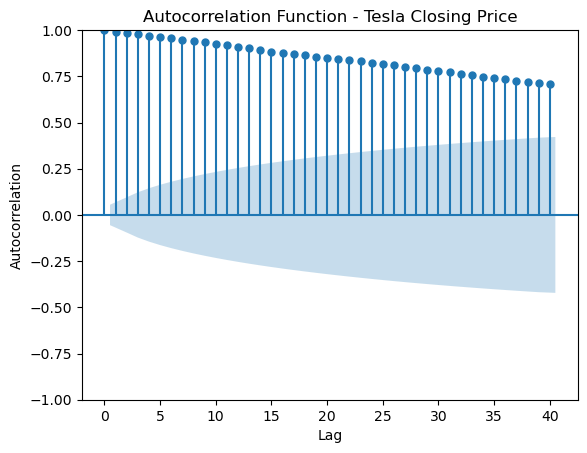

Potentially significant lags:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]


In [117]:
# Calculate autocorrelation for Tesla closing price
tsla_acf = acf(
    df_features['tsla_close'].dropna(),
    nlags=40,
    fft=True
)

# Plot ACF
plt.figure(figsize=(12, 5))

plot_acf(
    df_features['tsla_close'].dropna(),
    lags=40,
    alpha=0.05
)

plt.title('Autocorrelation Function - Tesla Closing Price')
plt.xlabel('Lag')
plt.ylabel('Autocorrelation')
plt.show()

# Identify potentially significant lags
significant_lags = [
    lag for lag in range(1, len(tsla_acf))
    if abs(tsla_acf[lag]) > 1.96 / np.sqrt(
        len(df_features['tsla_close'].dropna())
    )
]

print("Potentially significant lags:")
print(significant_lags)

In [118]:
# Inspecting tesla log returns: 

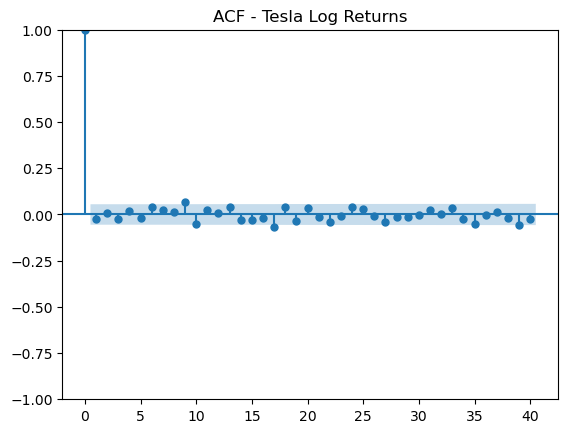

In [120]:
tsla_returns = np.log(df_features['tsla_close']).diff().dropna()

plot_acf(tsla_returns, lags=40, alpha=0.05)
plt.title('ACF - Tesla Log Returns')
plt.show()

In [123]:
### 8.2 Rolling Statistics: 

In [124]:
# Rolling mean: 

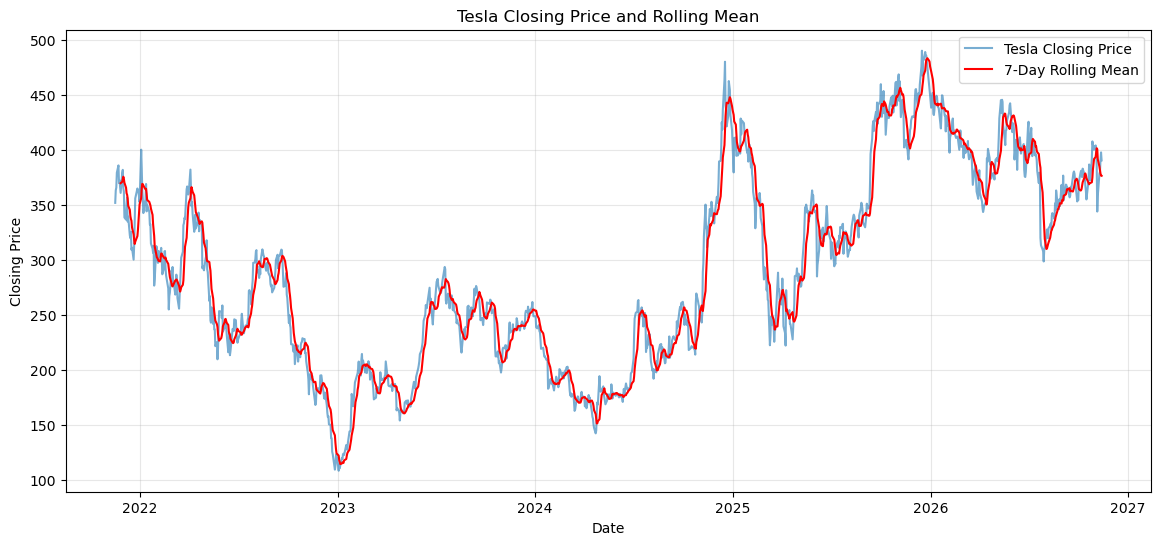

In [125]:
df_features['tsla_rolling_mean_7'] = (
    df_features['tsla_close']
    .shift(1)
    .rolling(window=7)
    .mean()
)

# Visualize rolling mean
plt.figure(figsize=(14, 6))

plt.plot(
    df_features.index,
    df_features['tsla_close'],
    label='Tesla Closing Price',
    alpha=0.6
)

plt.plot(
    df_features.index,
    df_features['tsla_rolling_mean_7'],
    label='7-Day Rolling Mean',
    color='red'
)

plt.title('Tesla Closing Price and Rolling Mean')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [126]:
# Rolling stdev: 

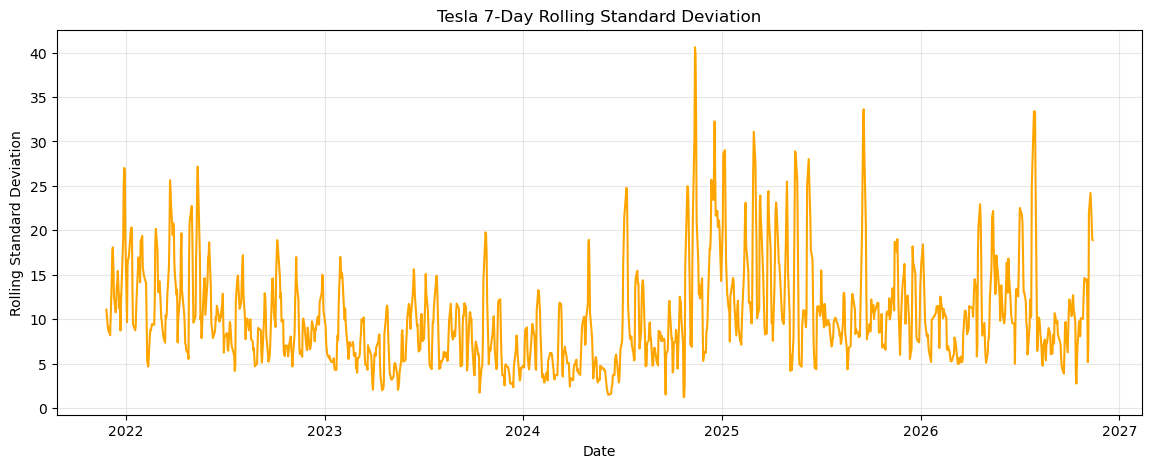

In [128]:
df_features['tsla_rolling_std_7'] = (
    df_features['tsla_close']
    .shift(1)
    .rolling(window=7)
    .std()
)

plt.figure(figsize=(14, 5))

plt.plot(
    df_features.index,
    df_features['tsla_rolling_std_7'],
    color='orange'
)

plt.title('Tesla 7-Day Rolling Standard Deviation')
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation')
plt.grid(alpha=0.3)
plt.show()

In [129]:
# Exponential moving average: 

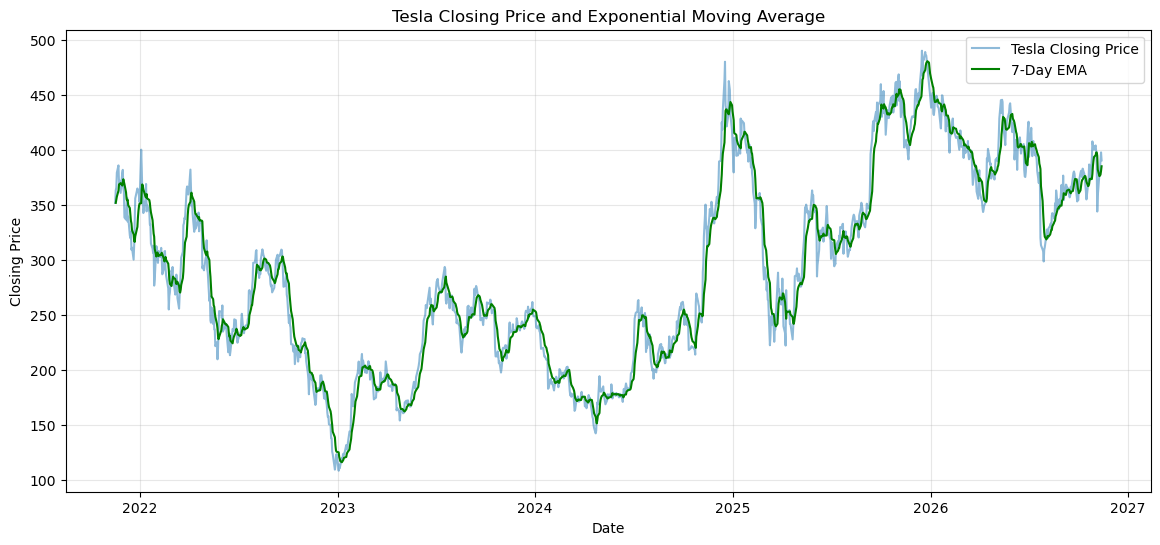

In [130]:
df_features['tsla_ema_7'] = (
    df_features['tsla_close']
    .shift(1)
    .ewm(span=7, adjust=False)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    df_features.index,
    df_features['tsla_close'],
    label='Tesla Closing Price',
    alpha=0.5
)

plt.plot(
    df_features.index,
    df_features['tsla_ema_7'],
    label='7-Day EMA',
    color='green'
)

plt.title('Tesla Closing Price and Exponential Moving Average')
plt.xlabel('Date')
plt.ylabel('Closing Price')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [131]:
### 8.3 Differencing and reurningn features: 

In [132]:
# 1st difference: 

In [134]:
df_features['tsla_first_diff'] = (
    df_features['tsla_close'].diff()
)

print(df_features[['tsla_close', 'tsla_first_diff']].head(10))

            tsla_close  tsla_first_diff
Date                                   
2021-11-16  351.576660              NaN
2021-11-17  363.003326        11.426666
2021-11-18  365.459991         2.456665
2021-11-19  379.019989        13.559998
2021-11-22  385.623322         6.603333
2021-11-23  369.676666       -15.946655
2021-11-24  372.000000         2.323334
2021-11-26  360.640015       -11.359985
2021-11-29  378.996674        18.356659
2021-11-30  381.586670         2.589996


In [136]:
# %-change: 

In [137]:
df_features['tsla_pct_change'] = (
    df_features['tsla_close'].pct_change() * 100
)

print(df_features[['tsla_close', 'tsla_pct_change']].head(10))

            tsla_close  tsla_pct_change
Date                                   
2021-11-16  351.576660              NaN
2021-11-17  363.003326         3.250121
2021-11-18  365.459991         0.676761
2021-11-19  379.019989         3.710392
2021-11-22  385.623322         1.742212
2021-11-23  369.676666        -4.135293
2021-11-24  372.000000         0.628477
2021-11-26  360.640015        -3.053760
2021-11-29  378.996674         5.090023
2021-11-30  381.586670         0.683382


In [138]:
# Log returns: 

In [139]:
df_features['tsla_log_return'] = (
    np.log(df_features['tsla_close']).diff()
)

print(df_features[['tsla_close', 'tsla_log_return']].head(10))

            tsla_close  tsla_log_return
Date                                   
2021-11-16  351.576660              NaN
2021-11-17  363.003326         0.031984
2021-11-18  365.459991         0.006745
2021-11-19  379.019989         0.036432
2021-11-22  385.623322         0.017272
2021-11-23  369.676666        -0.042232
2021-11-24  372.000000         0.006265
2021-11-26  360.640015        -0.031014
2021-11-29  378.996674         0.049647
2021-11-30  381.586670         0.006811


In [140]:
# Visualizing differencing and return features: 

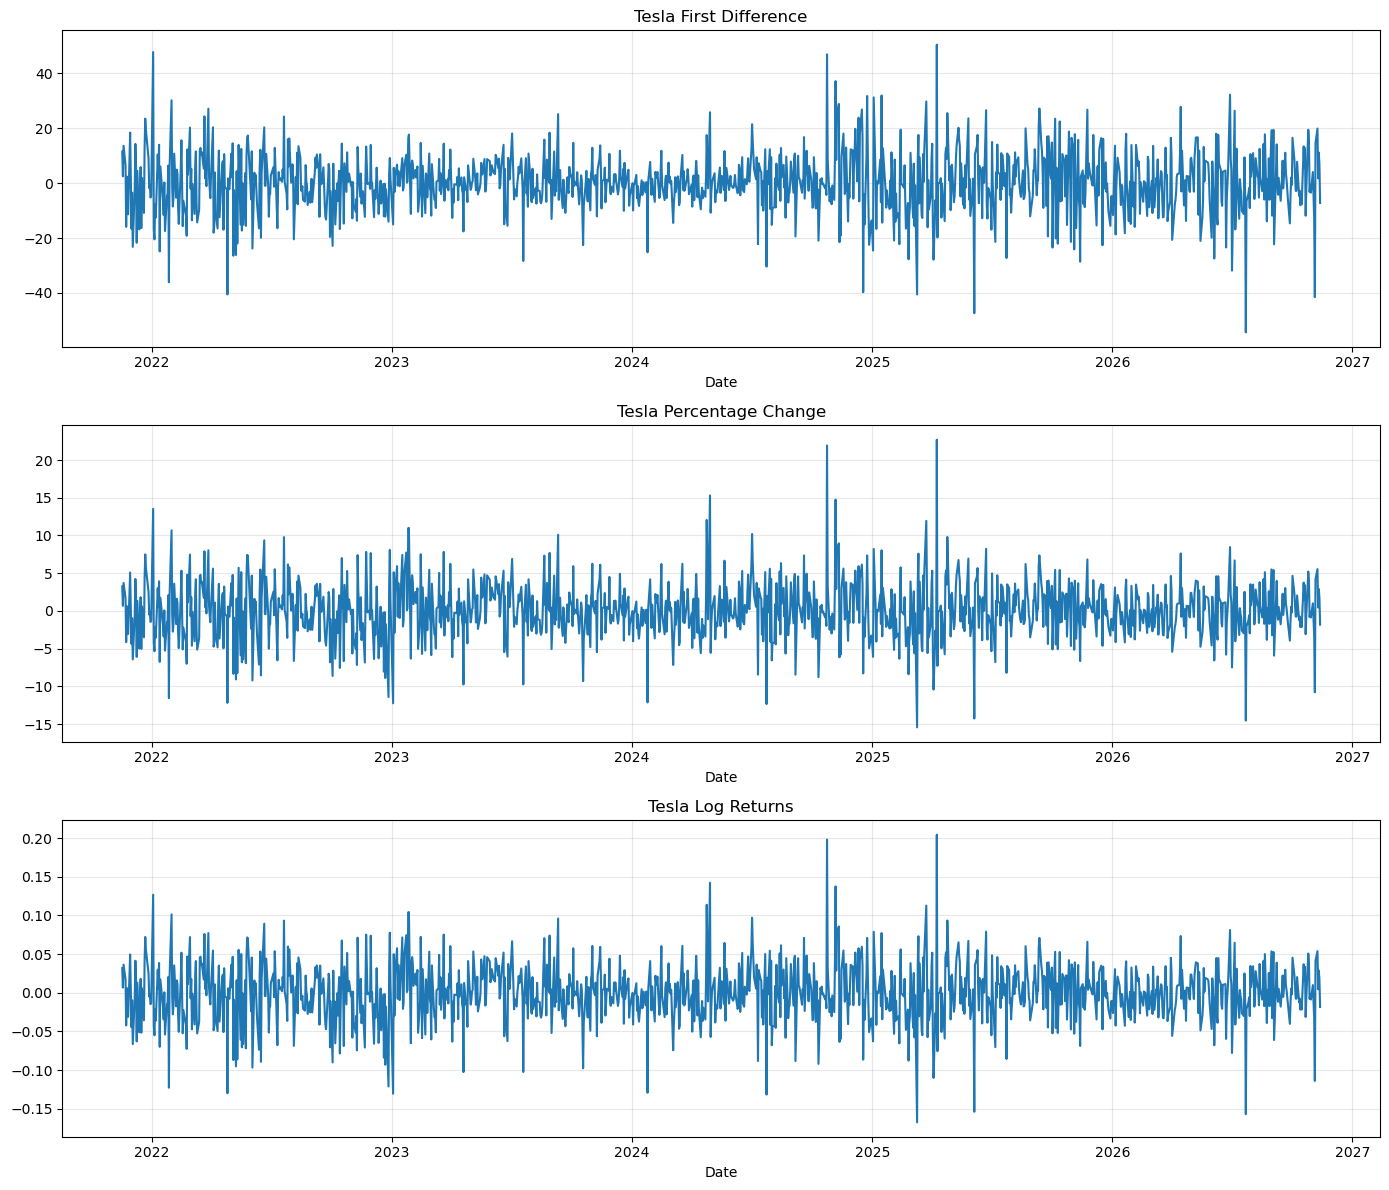

In [142]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))

axes[0].plot(df_features.index, df_features['tsla_first_diff'])
axes[0].set_title('Tesla First Difference')

axes[1].plot(df_features.index, df_features['tsla_pct_change'])
axes[1].set_title('Tesla Percentage Change')

axes[2].plot(df_features.index, df_features['tsla_log_return'])
axes[2].set_title('Tesla Log Returns')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.set_xlabel('Date')

plt.tight_layout()
plt.show()

In [143]:
### 8.4 Final feature engineering dataset: 

In [145]:
# Display all engineered features
feature_columns = [
    'tsla_close',
    'tsla_lag1',
    'tsla_lag7',
    'tsla_lag30',
    'tsla_rolling_mean_7',
    'tsla_rolling_std_7',
    'tsla_ema_7',
    'tsla_first_diff',
    'tsla_pct_change',
    'tsla_log_return'
]

display(df_features[feature_columns].head(35))

# Check missing values introduced by feature engineering
print("Missing values after feature engineering:")
print(df_features[feature_columns].isnull().sum())

,tsla_close,tsla_lag1,tsla_lag7,tsla_lag30,tsla_rolling_mean_7,tsla_rolling_std_7,tsla_ema_7,tsla_first_diff,tsla_pct_change,tsla_log_return
Date,,,,,,,,,,
2021-11-16,351.576660,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2021-11-17,363.003326,351.576660,NaN,NaN,NaN,NaN,351.576660,11.426666,3.250121,0.031984
2021-11-18,365.459991,363.003326,NaN,NaN,NaN,NaN,354.433327,2.456665,0.676761,0.006745
2021-11-19,379.019989,365.459991,NaN,NaN,NaN,NaN,357.189993,13.559998,3.710392,0.036432
2021-11-22,385.623322,379.019989,NaN,NaN,NaN,NaN,362.647492,6.603333,1.742212,0.017272
2021-11-23,369.676666,385.623322,NaN,NaN,NaN,NaN,368.391449,-15.946655,-4.135293,-0.042232
2021-11-24,372.000000,369.676666,NaN,NaN,NaN,NaN,368.712754,2.323334,0.628477,0.006265
2021-11-26,360.640015,372.000000,351.576660,NaN,369.479994,11.080348,369.534565,-11.359985,-3.053760,-0.031014
2021-11-29,378.996674,360.640015,363.003326,NaN,370.774758,8.967772,367.310928,18.356659,5.090023,0.049647


Missing values after feature engineering:
tsla_close              0
tsla_lag1               1
tsla_lag7               7
tsla_lag30             30
tsla_rolling_mean_7     7
tsla_rolling_std_7      7
tsla_ema_7              1
tsla_first_diff         1
tsla_pct_change         1
tsla_log_return         1
dtype: int64


In [146]:
# Preparing the dataset for prediction: 

In [147]:
# Remove rows with missing engineered features
df_model = df_features.dropna(
    subset=feature_columns
).copy()

print("Original dataset shape:", df.shape)
print("Model dataset shape:", df_model.shape)

display(df_model.head())

Original dataset shape: (1254, 4)
Model dataset shape: (1224, 13)


,tsla_close,oil_close,lit_close,nasdaq_close,tsla_lag1,tsla_lag7,tsla_lag30,tsla_rolling_mean_7,tsla_rolling_std_7,tsla_ema_7,tsla_first_diff,tsla_pct_change,tsla_log_return
Date,,,,,,,,,,,,,
2021-12-30,356.779999,76.989998,81.588852,15741.559570,362.063324,299.980011,351.576660,342.044761,26.407633,348.944075,-5.283325,-1.459227,-0.014700
2021-12-31,352.260010,75.209999,81.127686,15644.969727,356.779999,312.843323,363.003326,350.159045,19.021792,350.903056,-4.519989,-1.266884,-0.012750
2022-01-03,399.926666,76.080002,82.559235,15832.799805,352.260010,336.290009,365.459991,355.790000,9.669270,351.242295,47.666656,13.531668,0.126912
2022-01-04,383.196655,76.989998,82.136490,15622.719727,399.926666,355.666656,379.019989,364.880951,16.074030,363.413388,-16.730011,-4.183270,-0.042733
2022-01-05,362.706665,77.849998,78.264572,15100.169922,383.196655,364.646667,385.623322,368.813808,16.795520,368.359204,-20.489990,-5.347121,-0.054954


# Part 3 — Time-Series Feature Engineering

This section focuses on generating additional features from existing time-series observations to capture temporal dependencies, rolling statistics, trends and changes over time.

## 9. Practical Exercises and Conclusion

### Practical Exercises

- Compare additive and multiplicative decomposition.
- Compare missing-value imputation methods.
- Investigate volatility using rolling windows.
- Compare stationarity before and after transformations.

### Final Summary

- Summarize descriptive statistics and correlations.
- Highlight trends and seasonal patterns.
- Report ADF stationarity results.
- Summarize outlier and missing-data findings.
- Present the main conclusions.

In [148]:
### Comparing additive and multiplicative decomposition: 

            Model  Residual Mean  Residual Standard Deviation  \
0        Additive        -0.6381                      37.1884   
1  Multiplicative         0.9908                       0.1366   

   Residual Variance  Residual RMSE  
0          1382.9785        36.8125  
1             0.0186         1.0000  


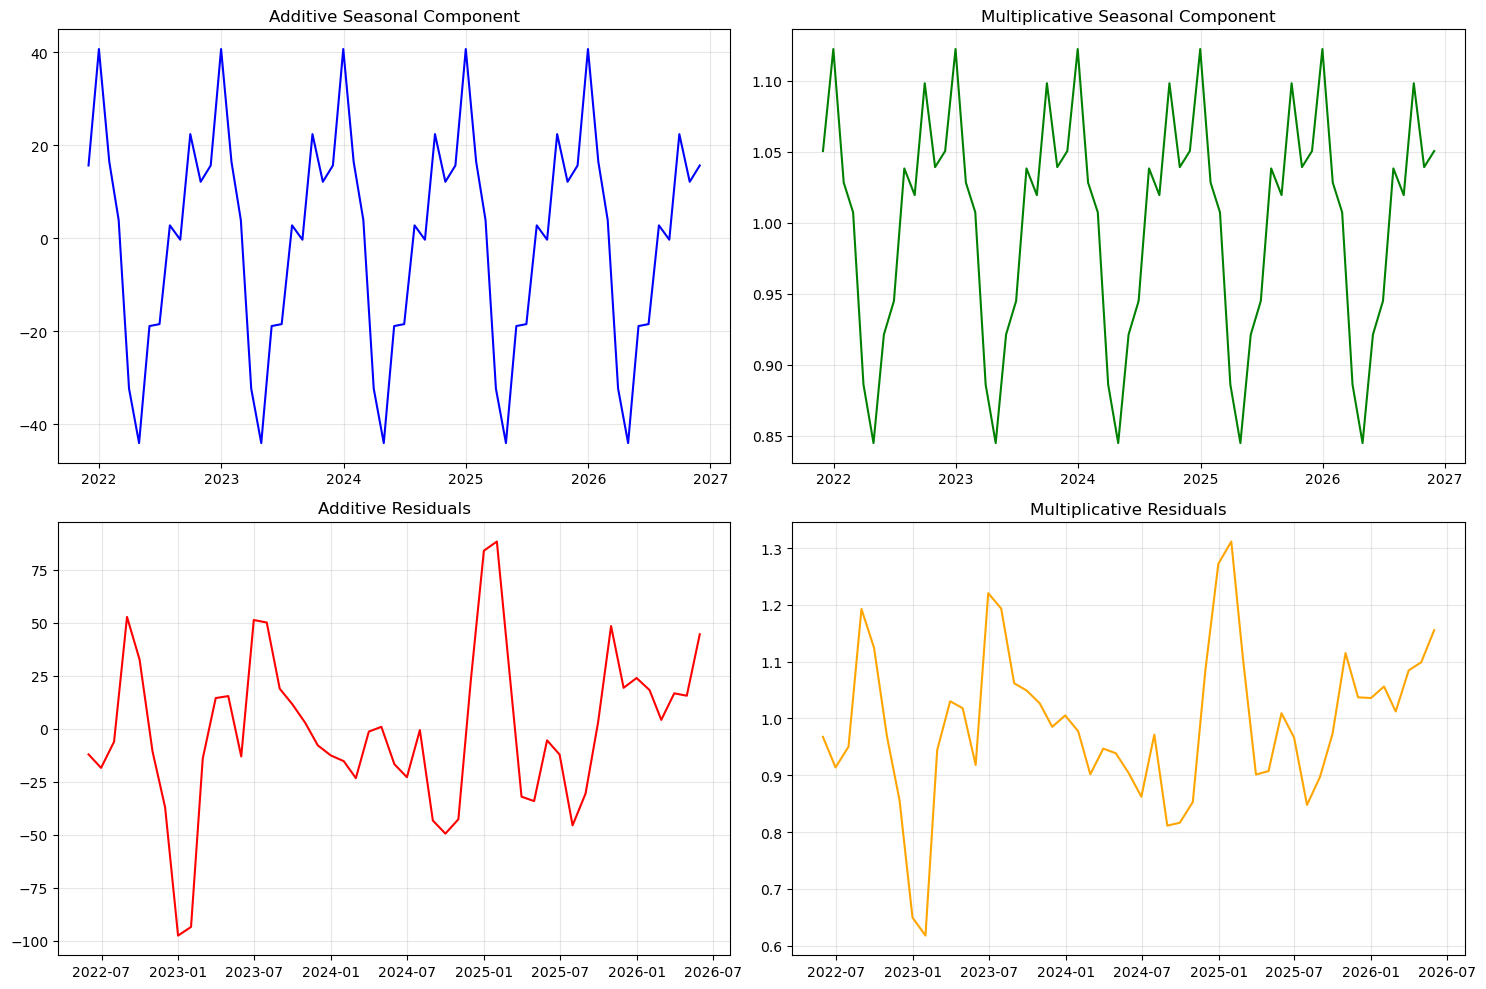

In [156]:
decomposition_comparison = pd.DataFrame({
    'Model': ['Additive', 'Multiplicative'],
    'Residual Mean': [
        additive_decomposition.resid.mean(),
        multiplicative_decomposition.resid.mean()
    ],
    'Residual Standard Deviation': [
        additive_decomposition.resid.std(),
        multiplicative_decomposition.resid.std()
    ],
    'Residual Variance': [
        additive_decomposition.resid.var(),
        multiplicative_decomposition.resid.var()
    ],
    'Residual RMSE': [
        np.sqrt((additive_decomposition.resid.dropna() ** 2).mean()),
        np.sqrt((multiplicative_decomposition.resid.dropna() ** 2).mean())
    ]
})

print(decomposition_comparison.round(4))

# Visually comparing: 

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(
    additive_decomposition.seasonal,
    color='blue'
)
axes[0, 0].set_title('Additive Seasonal Component')

axes[0, 1].plot(
    multiplicative_decomposition.seasonal,
    color='green'
)
axes[0, 1].set_title('Multiplicative Seasonal Component')

axes[1, 0].plot(
    additive_decomposition.resid,
    color='red'
)
axes[1, 0].set_title('Additive Residuals')

axes[1, 1].plot(
    multiplicative_decomposition.resid,
    color='orange'
)
axes[1, 1].set_title('Multiplicative Residuals')

for ax in axes.flatten():
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [157]:
### Comparing missing-value imputation methdos: 

In [158]:
# Create a copy of Tesla prices

tsla_original = df['tsla_close'].copy()

# Simulate missing values
np.random.seed(42)

missing_indices = np.random.choice(
    tsla_original.index,
    size=int(len(tsla_original) * 0.05),
    replace=False
)

tsla_missing = tsla_original.copy()
tsla_missing.loc[missing_indices] = np.nan

print("Simulated missing values:", tsla_missing.isna().sum())

Simulated missing values: 62


In [159]:
### Applying imputation methdods: 

                 Method     RMSE
0  Linear Interpolation   8.7053
1          Rolling Mean  16.5708
2          Monthly Mean  77.0756


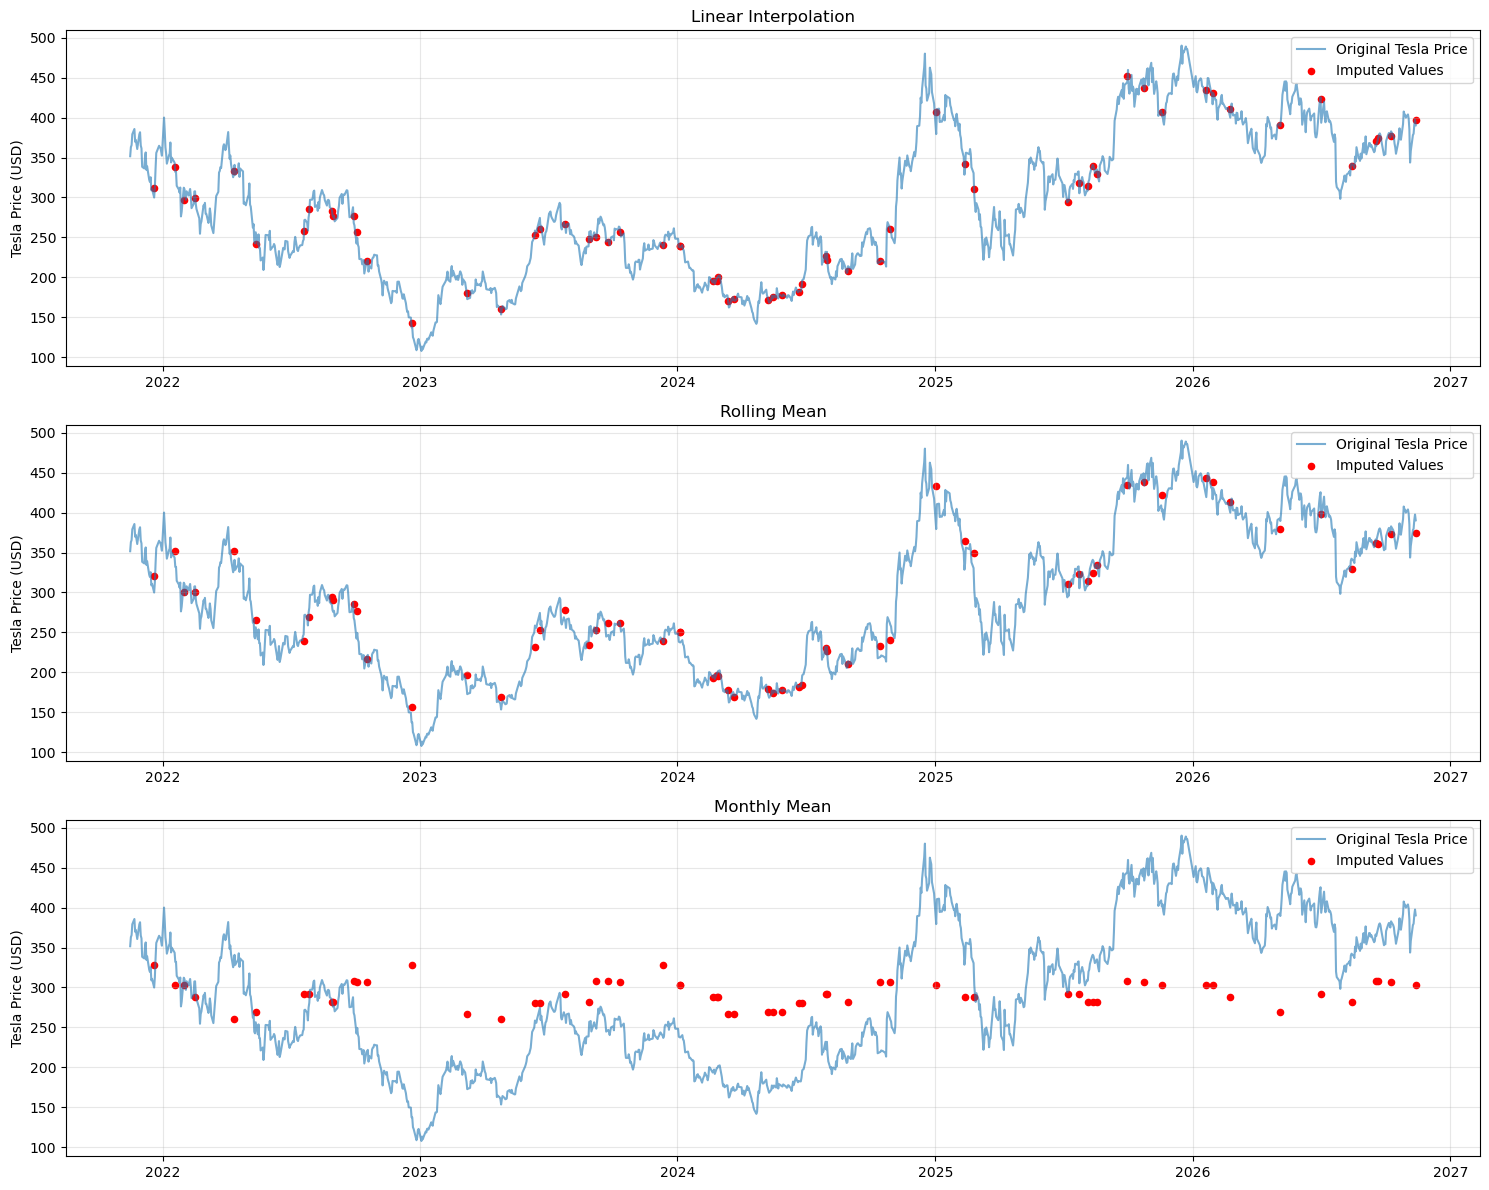

In [161]:
# Linear interpolation

linear_imputed = tsla_missing.interpolate(
    method='linear'
)

# Rolling mean imputation

rolling_mean = tsla_missing.rolling(
    window=7,
    min_periods=1
).mean()

rolling_imputed = tsla_missing.fillna(rolling_mean)

# Monthly mean imputation

monthly_means = tsla_missing.groupby(
    tsla_missing.index.month
).transform('mean')

monthly_imputed = tsla_missing.fillna(monthly_means)

# Compare results using RMSE

imputation_results = pd.DataFrame({
    'Method': [
        'Linear Interpolation',
        'Rolling Mean',
        'Monthly Mean'
    ],
    'RMSE': [
        np.sqrt(np.mean(
            (tsla_original.loc[missing_indices] -
             linear_imputed.loc[missing_indices]) ** 2
        )),
        np.sqrt(np.mean(
            (tsla_original.loc[missing_indices] -
             rolling_imputed.loc[missing_indices]) ** 2
        )),
        np.sqrt(np.mean(
            (tsla_original.loc[missing_indices] -
             monthly_imputed.loc[missing_indices]) ** 2
        ))
    ]
})

print(imputation_results.round(4))

# Visualizing them: 

fig, axes = plt.subplots(3, 1, figsize=(15, 12))

methods = [
    ('Linear Interpolation', linear_imputed),
    ('Rolling Mean', rolling_imputed),
    ('Monthly Mean', monthly_imputed)
]

for ax, (name, imputed) in zip(axes, methods):

    ax.plot(
        tsla_original,
        label='Original Tesla Price',
        alpha=0.6
    )

    ax.scatter(
        tsla_missing.index[tsla_missing.isna()],
        imputed.loc[tsla_missing.isna()],
        color='red',
        label='Imputed Values',
        s=20
    )

    ax.set_title(name)
    ax.set_ylabel('Tesla Price (USD)')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [162]:
### Investigating volatility: 

            Daily Returns  7-Day Volatility  30-Day Volatility  \
Date                                                             
2026-11-09       0.053879          0.055559           0.033000   
2026-11-10       0.004566          0.055806           0.032883   
2026-11-11       0.028706          0.057206           0.033228   
2026-11-12       0.016771          0.057579           0.033303   
2026-11-13      -0.018358          0.056350           0.032583   

            90-Day Volatility  
Date                           
2026-11-09           0.033117  
2026-11-10           0.032385  
2026-11-11           0.032254  
2026-11-12           0.032219  
2026-11-13           0.032104  


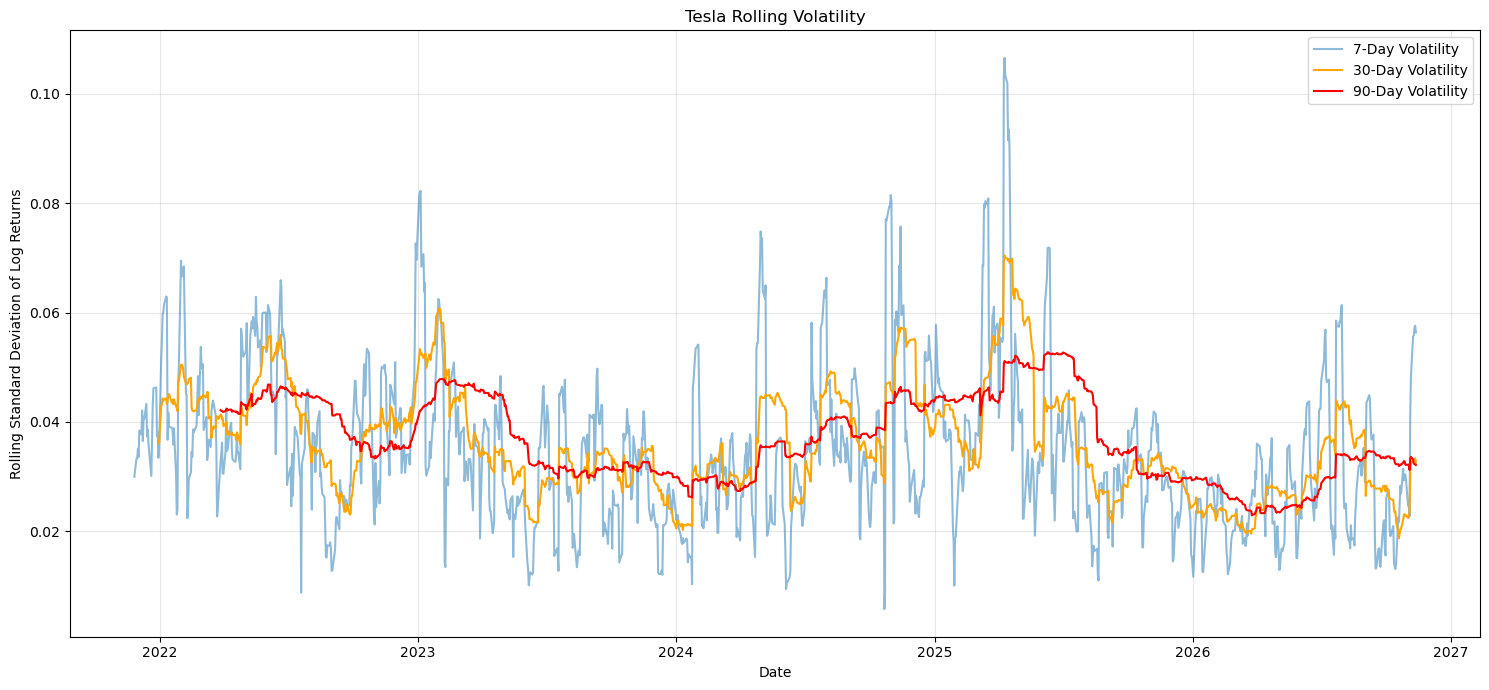

In [166]:
# Calculating rolling volatility: 

tsla_returns = np.log(
    df['tsla_close']
).diff()

# Calculate rolling volatility

df_volatility = pd.DataFrame(index=df.index)

df_volatility['Daily Returns'] = tsla_returns

df_volatility['7-Day Volatility'] = (
    tsla_returns.rolling(window=7).std()
)

df_volatility['30-Day Volatility'] = (
    tsla_returns.rolling(window=30).std()
)

df_volatility['90-Day Volatility'] = (
    tsla_returns.rolling(window=90).std()
)

print(df_volatility.tail())

# Visualizing rolling volatility: 

plt.figure(figsize=(15, 7))

plt.plot(
    df_volatility['7-Day Volatility'],
    label='7-Day Volatility',
    alpha=0.5
)

plt.plot(
    df_volatility['30-Day Volatility'],
    label='30-Day Volatility',
    color='orange'
)

plt.plot(
    df_volatility['90-Day Volatility'],
    label='90-Day Volatility',
    color='red'
)

plt.title('Tesla Rolling Volatility')
plt.xlabel('Date')
plt.ylabel('Rolling Standard Deviation of Log Returns')

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [167]:
### Comparing volatility statistics: 

In [168]:

volatility_summary = df_volatility[
    ['7-Day Volatility', '30-Day Volatility', '90-Day Volatility']
].describe()

print(volatility_summary.round(5))

       7-Day Volatility  30-Day Volatility  90-Day Volatility
count        1247.00000         1224.00000         1164.00000
mean            0.03465            0.03612            0.03681
std             0.01459            0.00981            0.00755
min             0.00574            0.01871            0.02289
25%             0.02421            0.02870            0.03057
50%             0.03275            0.03444            0.03539
75%             0.04145            0.04281            0.04394
max             0.10657            0.07046            0.05273


In [170]:
### Comparing stationarity before and after transformation: 

In [171]:
stationarity_comparison = []

for col in columns:

    original_result = adfuller(df[col].dropna())

    log_result = adfuller(
        df_log[f'{col}_log'].dropna()
    )

    diff_result = adfuller(
        df_diff[f'{col}_diff'].dropna()
    )

    stationarity_comparison.extend([
        {
            'Variable': col,
            'Transformation': 'Original',
            'ADF Statistic': original_result[0],
            'p-value': original_result[1],
            'Stationarity': 'Stationary' if original_result[1] <= 0.05 else 'Non-stationary'
        },
        {
            'Variable': col,
            'Transformation': 'Log',
            'ADF Statistic': log_result[0],
            'p-value': log_result[1],
            'Stationarity': 'Stationary' if log_result[1] <= 0.05 else 'Non-stationary'
        },
        {
            'Variable': col,
            'Transformation': 'Log + First Difference',
            'ADF Statistic': diff_result[0],
            'p-value': diff_result[1],
            'Stationarity': 'Stationary' if diff_result[1] <= 0.05 else 'Non-stationary'
        }
    ])

stationarity_comparison_df = pd.DataFrame(
    stationarity_comparison
)

print(stationarity_comparison_df.round(5))

        Variable          Transformation  ADF Statistic  p-value  \
0     tsla_close                Original       -2.05833  0.26160   
1     tsla_close                     Log       -2.01797  0.27875   
2     tsla_close  Log + First Difference      -36.21856  0.00000   
3      oil_close                Original       -2.51961  0.11078   
4      oil_close                     Log       -2.41484  0.13759   
5      oil_close  Log + First Difference       -7.66928  0.00000   
6      lit_close                Original       -2.21738  0.20000   
7      lit_close                     Log       -1.92039  0.32253   
8      lit_close  Log + First Difference      -36.30106  0.00000   
9   nasdaq_close                Original       -0.16733  0.94231   
10  nasdaq_close                     Log       -0.34173  0.91938   
11  nasdaq_close  Log + First Difference      -36.64738  0.00000   

      Stationarity  
0   Non-stationary  
1   Non-stationary  
2       Stationary  
3   Non-stationary  
4   Non-st

In [172]:
### Final sumamry: 

In [173]:
# Descriptive statistics and correlations: 

In [174]:
# Descriptive statistics

print("DESCRIPTIVE STATISTICS")
display(df[columns].describe().round(3))

# Correlation with Tesla

print("\nCORRELATIONS WITH TESLA")
display(
    df[columns].corr()['tsla_close']
    .sort_values(ascending=False)
    .round(3)
)

DESCRIPTIVE STATISTICS


,tsla_close,oil_close,lit_close,nasdaq_close
count,1254.000,1254.000,1254.000,1254.000
mean,290.110,79.239,58.023,17350.548
std,88.044,13.492,14.557,4873.924
min,108.100,55.270,31.486,10213.290
25%,219.233,69.660,43.638,13280.010
50%,276.850,77.530,60.445,16374.435
75%,361.777,86.908,69.637,21367.788
max,489.880,123.700,91.699,27599.789



CORRELATIONS WITH TESLA


tsla_close      1.000
nasdaq_close    0.750
lit_close       0.347
oil_close      -0.145
Name: tsla_close, dtype: float64

In [175]:
### highlighting seasonal trends and patterns: 

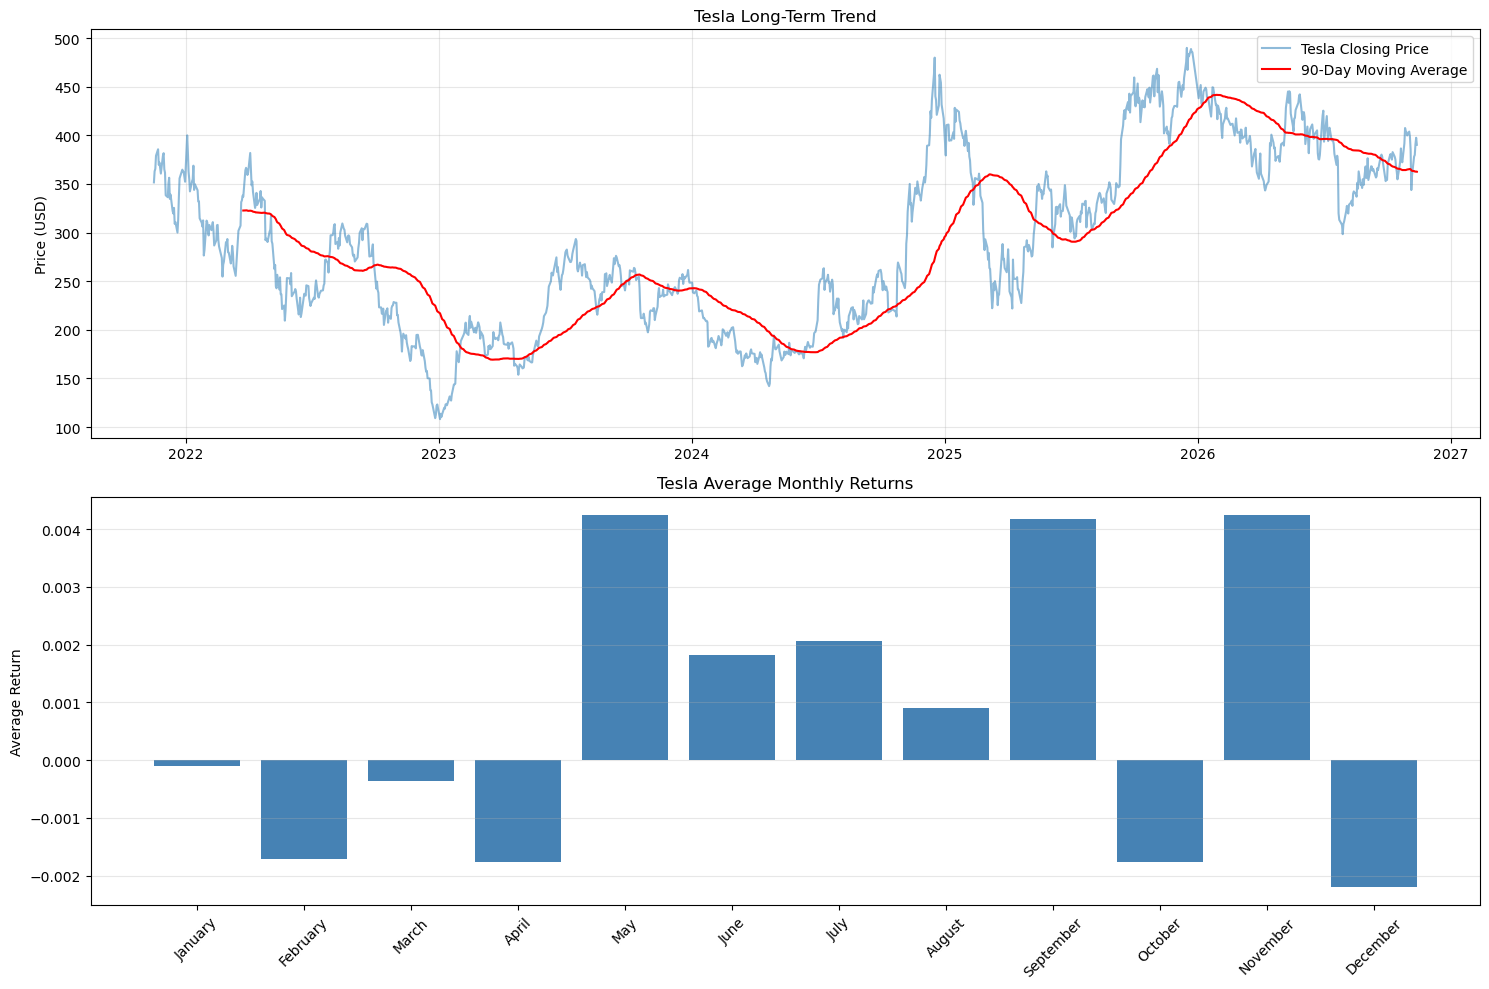

In [176]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))

# Long-term Tesla trend

axes[0].plot(
    tsla,
    label='Tesla Closing Price',
    alpha=0.5
)

axes[0].plot(
    tsla.rolling(90).mean(),
    label='90-Day Moving Average',
    color='red'
)

axes[0].set_title('Tesla Long-Term Trend')
axes[0].set_ylabel('Price (USD)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# Monthly average returns

axes[1].bar(
    monthly_returns.index,
    monthly_returns.values,
    color='steelblue'
)

axes[1].set_title('Tesla Average Monthly Returns')
axes[1].set_ylabel('Average Return')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [177]:
### Summarizing outlier and missing-data findings: 

In [178]:
# Outlier summary

outlier_summary = pd.DataFrame({
    'Z-Score Outliers': outliers_z.sum(),
    'Rolling IQR Outliers': outliers_iqr.sum()
})

print("OUTLIER SUMMARY")
display(outlier_summary)

# Missing data summary

missing_summary = pd.DataFrame({
    'Missing Count': df[columns].isnull().sum(),
    'Missing Percentage': df[columns].isnull().mean() * 100
})

print("\nMISSING DATA SUMMARY")
display(missing_summary)

# Date gaps

print("\nNUMBER OF LARGE DATE GAPS:", len(large_gaps))

OUTLIER SUMMARY


,Z-Score Outliers,Rolling IQR Outliers
tsla_close,0,114
oil_close,5,85
lit_close,0,72
nasdaq_close,0,69



MISSING DATA SUMMARY


,Missing Count,Missing Percentage
tsla_close,0,0.0
oil_close,0,0.0
lit_close,0,0.0
nasdaq_close,0,0.0



NUMBER OF LARGE DATE GAPS: 0


In [179]:
# Final Tesla analysis summary: 

In [180]:
print("=" * 60)
print("TESLA STOCK PRICE ANALYSIS - FINAL SUMMARY")
print("=" * 60)

print("\n1. DATASET INFORMATION")

print("Observations:", len(df))
print("Start Date:", df.index.min().date())
print("End Date:", df.index.max().date())

print("\n2. TESLA DESCRIPTIVE STATISTICS")

print("Mean:", round(df['tsla_close'].mean(), 2))
print("Median:", round(df['tsla_close'].median(), 2))
print("Standard Deviation:", round(df['tsla_close'].std(), 2))
print("Minimum:", round(df['tsla_close'].min(), 2))
print("Maximum:", round(df['tsla_close'].max(), 2))

print("\n3. CORRELATIONS WITH TESLA")

print(correlation_matrix['tsla_close'].round(3))

print("\n4. STATIONARITY")

print(stationarity_comparison_df[
    stationarity_comparison_df['Variable'] == 'tsla_close'
][['Transformation', 'ADF Statistic', 'p-value', 'Stationarity']])

print("\n5. OUTLIERS")

print(outlier_summary)

print("\n6. MISSING DATA")

print(missing_summary)

print("\n7. VOLATILITY")

print(df_volatility[
    ['7-Day Volatility', '30-Day Volatility', '90-Day Volatility']
].describe().round(5))

print("\n" + "=" * 60)
print("END OF ANALYSIS")
print("=" * 60)

TESLA STOCK PRICE ANALYSIS - FINAL SUMMARY

1. DATASET INFORMATION
Observations: 1254
Start Date: 2021-11-16
End Date: 2026-11-13

2. TESLA DESCRIPTIVE STATISTICS
Mean: 290.11
Median: 276.85
Standard Deviation: 88.04
Minimum: 108.1
Maximum: 489.88

3. CORRELATIONS WITH TESLA
tsla_close      1.000
oil_close      -0.145
lit_close       0.347
nasdaq_close    0.750
Name: tsla_close, dtype: float64

4. STATIONARITY
           Transformation  ADF Statistic   p-value    Stationarity
0                Original      -2.058329  0.261597  Non-stationary
1                     Log      -2.017967  0.278751  Non-stationary
2  Log + First Difference     -36.218557  0.000000      Stationary

5. OUTLIERS
              Z-Score Outliers  Rolling IQR Outliers
tsla_close                   0                   114
oil_close                    5                    85
lit_close                    0                    72
nasdaq_close                 0                    69

6. MISSING DATA
              Missing C